<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_BackdoorDetection_Zhang2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Black-box backdoor detection in quantum neural networks by dose-response Monte Carlo testing: Zhang et al. 2026 step by step

This notebook re-implements, runs and checks the defence of

> Yibin Zhang, Lili Yan, Zhiwei Sheng, Jiayu Zhao and Yan Chang,
> "Black-box backdoor detection in quantum neural networks via dose-response Monte Carlo testing",
> *Quantum Science and Technology* 11 (2026) 035026. https://doi.org/10.1088/2058-9565/ae7b80

The authors publish no code or data ("available on reasonable request"), so everything below is written from the method as the paper describes it, with the software stack
it names: **PennyLane** circuits, amplitude encoding of **MNIST** digits resized to 16 x 16, and four-class subsets.

**What the problem is, in plain words.** A company downloads a trained quantum classifier from a third party. The supplier may have slipped a **backdoor** into it: the model behaves
normally on clean images but outputs the attacker's *target class* whenever a secret *trigger* (a small pattern or a faint global noise pattern) is present. The buyer can only
send inputs to the model and read back the **four class probabilities**; there is no access to parameters, gradients, quantum states or raw measurement bitstrings.

**The paper's idea (dose-response).** The buyer owns a small trusted clean pool *Dc*, a clean reference model of the same architecture, and a suspect pool *Du* of unknown content. The buyer builds batches with an
increasing share rho of suspect inputs (the "dose"), and compares how often the model under test and the reference predict each class (the "response"). If *Du* contains trigger-bearing inputs and
the model is backdoored, one class (the target) is predicted more and more often as rho grows. Static differences between two independently trained models are removed by a
**difference-in-differences** step; shot noise and batch randomness are averaged out by **Monte Carlo resampling**; a one-sided **sign test** with **Holm-Bonferroni** correction controls the false-alarm
rate over all (rho, class) pairs; an **effect-size gate** and a **cold-zone** check turn the evidence into a *Detected* / *Pass* verdict and a target-class estimate.

**What the notebook does**

1. Downloads MNIST, builds the two four-class subsets of the paper (digits 1,3,7,9 for Q-FGSM; digits 0,1,2,3 for QUAP and PATCH), resizes to 16 x 16 and amplitude-encodes into 8 data qubits (+2 readout qubits = 10 qubits).
2. Builds the four QNN architectures (QNN1, QNN3, QNN6, QNN7) as PennyLane circuits and a fast, asserted-equal torch simulator used for training.
3. Implements the three backdoor attacks (Q-FGSM universal perturbation, query-only QUAP universal perturbation, 4 x 4 PATCH), trains clean references, clean controls and backdoored models at several poisoning rates and seeds.
4. Implements **Algorithm 1** (mixed batches, shot noise, difference-in-differences, Monte Carlo, sign tests, Holm, three-gate decision rule) and runs it on every trained instance.
5. Re-draws the paper's tables and figures (Tables 3-14, heat-maps of Figures 2-5, ROC/PR of Figures 6-8, contamination sweep of Figure 9), adds a classical-model control, and compares every number with the paper claim by claim.

**How to run.** Open in Google Colab (button above), choose a **CPU** runtime and use *Runtime -> Run all*. With `FAST_MODE = True` the notebook is a class demo (a subset of the paper's grid, one seed, small training sets; about 10 minutes on a CPU).
With `FAST_MODE = False` it runs the larger grid listed in the configuration cell. MNIST is public: no token is needed.

**What you get at the end.** Per-instance detection tables, the paper's aggregate metrics (sensitivity, specificity, AUC, AP, localisation) next to this notebook's, ablations, and a verdict "reproduced / not reached here / cannot be checked" for each checkable claim.

## The paper in one page

**Problem.** Black-box backdoor detection for QNNs when the interface exposes only the K-dimensional class-probability vector (or a finite-shot frequency estimate), with a small trusted clean pool *Dc*, a suspect pool *Du* (trigger prevalence pi unknown), and a matched-architecture clean reference model.

**Decision.** For a model under test: *Detected* / *Pass*, and when detected, an estimate of the target class.

**Method (Algorithm 1).** For each Monte Carlo replication m = 1..M and each mixing ratio rho in R = {0, 0.2, ..., 1.0}: build a class-balanced batch of N = 1000 inputs with a share rho from *Du* (Eq. 6), query the model under test and the reference with S = 1024 simulated shots per input
(`n ~ Multinomial(S, p)`, label = argmax n, Eq. 12), compute prediction-rate vectors PR (Eq. 8), the gap `Delta_c(rho) = PR_c(test) - PR_c(ref)` (Eq. 9) and the **DiD-aligned** gap `Delta_adj_c(rho) = Delta_c(rho) - Delta_c(0)` (Eq. 10).
Then for every (rho != 0, class c): one-sided sign test of `median(Delta_adj_c(rho)) > 0` over the M = 30 replications (Eq. 13), Holm-Bonferroni correction over the |H| = K(|R|-1) = 20 hypotheses, and at rho_max the rule
`gap* > tau`, `p* < alpha`, `cold* < tau_cold` with (tau, alpha, tau_cold) = (0.10, 0.05, -0.05) (Eqs. 15-17); the candidate class `c* = argmax mean Delta_adj_c(rho_max)` is the estimated target.

**Data.** MNIST resized 28 x 28 -> 16 x 16 (bilinear), pixels in [0,1], amplitude encoding on 8 qubits + 2 readout qubits; four-class subsets (Table 1): Q-FGSM digits (1,3,7,9), target class 2 (digit 7); QUAP and PATCH digits (0,1,2,3), target class 0 (digit 0).

**Models and attacks.** QNN1 (10 x StronglyEntanglingLayers, ring CNOT), QNN3 (20 layers Rot-Hadamard-CZ star), QNN6 (20 layers of a 10-rotation sequence + ring CNOT), QNN7 (20 layers hardware-efficient RX-RZ / chain CNOT / Rot); readout = two ancilla qubits in the computational basis.
Q-FGSM on QNN1 (poison rates 0-100 %), QUAP on QNN3/6/7 (0, 3, 5, 7 %), PATCH on QNN3 (0, 5, 10, 15 %); 5 seeds (20-24); 110 trained instances (85 backdoored, 25 clean).

**Claims to check.**

| # | Claim (paper) | Where |
|---|---|---|
| 1 | Sensitivity 0.906 (77/85), specificity 0.840 (21/25), precision 0.951, F1 0.928 at (0.10, 0.05, -0.05) | Sec. 5.6, Table 8 |
| 2 | AUC 0.954 (ROC of gap*), AP 0.986; per family AUC PATCH 1.000, Q-FGSM 1.000, QUAP 0.976 | Sec. 5.7, Figs 6-8 |
| 3 | Target class correctly localised in 98.7 % (76/77) of detections | Table 8 |
| 4 | Q-FGSM: 100 % specificity, 72 % sensitivity for 20-100 % poisoning; PATCH: 100 % / 100 %; QUAP p3-p7 sensitivity 100 / 100 / 93 % (QNN3/6/7); QUAP clean-control specificity 60 / 100 / 60 % | Tables 3-8 |
| 5 | Dose-response: the target-class aligned uplift grows with rho and with the poison rate; non-target classes are negative (hot/cold structure) | Figs 2-5 |
| 6 | The Holm floor is `20 * 2^-M`: with M <= 8 nothing can be detected, with M = 30 the smallest p is 1.86e-8 | Tables 9-10 |
| 7 | Removing the cold-zone gate adds a false positive; removing DiD, Holm or the sign test hardly changes the binary metrics | Table 9 |
| 8 | tau trade-off: sensitivity falls and specificity rises with tau in {0.05, 0.10, 0.15, 0.20} | Table 12 |
| 9 | With no triggered inputs in *Du* (pi = 0) there are no detections; power grows with pi | Sec. 5.11, Fig. 9 |
| 10 | Cross-architecture reference (QUAP): 96.7 % sensitivity, 80 % specificity | Table 14 |
| 11 | Clean-data accuracy of the QNNs is 90-95 % | Tables 3-7 |

## What follows the paper and what had to be chosen

The paper omits many training and attack details. Every row marked *CHOICE* is a decision of this notebook and is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | four-class MNIST subsets, 28 x 28 -> 16 x 16 | MNIST from the public Hugging Face mirror `ylecun/mnist`; digits (1,3,7,9) and (0,1,2,3); bilinear resize; same subsets and label mapping (Table 1) |
| Encoding and readout | amplitude encoding on 8 qubits, 2 ancilla readout qubits, 4 outcomes = classes | same: `AmplitudeEmbedding(normalize=True)` on wires 0-7; class = measured value of wires (8, 9), `2*q8 + q9` |
| QNN1 | 10 x StronglyEntanglingLayers, ring CNOT(i, i+1 mod n) | `qml.StronglyEntanglingLayers` on 10 wires with `ranges=[1]*10` (300 parameters) |
| QNN3 | depth 20, Hadamard-Rot-Hadamard, star CZ from the most significant qubit | as described (600 parameters); the CZ star is CZ(0, j), j = 1..9 |
| QNN6 | depth 20, 10-rotation sequence RX-RY-RZ-RZ-RY-RX-RX-RY-RZ-RX + ring CNOT | CHOICE: every qubit gets the whole 10-rotation sequence, each with its own angle (2,000 parameters) |
| QNN7 | depth 20, RX-RZ, linear-chain CNOT, Rot | as described (1,000 parameters) |
| Training of the QNNs | not stated | CHOICE: cross-entropy on the 4 readout probabilities, Adam, learning rate 0.05, batch 64, 3 epochs, weights initialised N(0, 0.1^2); **training sets of 2,000 images** instead of the full 24-25 thousand (CPU budget) |
| Poisoning rate | "poison rate" 0-100 % (Q-FGSM), 3-7 % (QUAP), 5-15 % (PATCH); semantics not stated | CHOICE: triggered copies of non-target training images are **appended** with the target label. QUAP/PATCH: `round(rate * n_train)` copies. Q-FGSM: `round(rate * n_target_class)` copies (so 100 % doubles the target class; a literal 100 % of the training set made the 3-epoch QNN collapse to the target class) |
| Q-FGSM trigger | global additive universal perturbation from a white-box gradient attack | CHOICE: iterated signed-gradient steps on the mean target cross-entropy against an attacker's clean QNN of the same architecture (trained with a different seed), L-infinity bound 0.15, 20 steps; chosen so that the trigger fools an independent clean model on roughly a third of the inputs, as in Table 3 |
| QUAP trigger | query-only universal perturbation | CHOICE: natural-evolution-strategy gradient estimates from probability queries only (40 iterations, 6 antithetic pairs, batches of 32 images), L-infinity bound 0.35 |
| PATCH trigger | 4 x 4 patch, lower-right corner of the 16 x 16 image, pattern not stated | CHOICE: constant grey value 0.4 in the 4 x 4 corner (a white patch was learned perfectly at 5 % poisoning, far from Table 7) |
| Pools *Dc*, *Du* | sizes not stated; *Du* synthetically triggered (pi = 1) with true labels kept | CHOICE: the 4-class MNIST **test** images are split (stratified) into 40 % evaluation (CDA, ASR), 30 % *Dc*, 30 % *Du*; every *Du* image receives the attack's trigger |
| Clean reference | independently trained clean model of the same architecture | same architecture and data subset, different initialisation and shuffling seed; the clean control (poison rate 0) is a third, separate clean model |
| Detector settings | M = 30, N = 1000 (250 per class), R = {0,...,1}, S = 1024, class-balanced mixing, (tau, alpha, tau_cold) = (0.10, 0.05, -0.05) | identical (ties in the sign test count as non-positive, so the smallest p is `2^-M`, as in the paper) |
| Seeds and instances | 5 seeds (20-24), 110 instances | FAST: 1 seed and a subset of the grid; full: 3 seeds and the whole grid (see the configuration cell) |
| QSentry-style baseline (Sec. 5.13) | needs per-qubit Pauli-Z activations | not reproduced (it uses stronger access than the probability-only interface) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, scipy, torch and Pillow.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" requests
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False         # True: class demo (subset of the grid, 1 seed, ~10 min on a CPU). False: the whole grid of the paper with 3 seeds (about 1-1.5 h on a CPU)
SEED      = 42            # CHOICE: seed of the data split, python/numpy/torch generators (the paper's seeds 20-24 are used for the model instances)
IBM_TOKEN = ""            # unused: the paper is a noise-free simulation with simulated shot noise, no hardware cell exists
DATA_DIR  = "mnist_data"  # MNIST cache (a few MB)

# --- fixed by the paper ---
N_QUBITS, N_DATA, K = 10, 8, 4                 # 8 data qubits (amplitude encoding of 16 x 16) + 2 readout qubits, 4 classes
RHOS      = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]     # mixing-ratio grid R
MC_RUNS   = 30                                  # M
BATCH_N   = 1000                                # N (250 per class with class-balanced mixing)
SHOTS     = 1024                                # S
TAU, ALPHA, TAU_COLD = 0.10, 0.05, -0.05
TARGETS   = {"A1379": 2, "B0123": 0}            # Table 1: target class (digit 7 for the Q-FGSM subset, digit 0 for the QUAP/PATCH subset)
DIGITS    = {"A1379": (1, 3, 7, 9), "B0123": (0, 1, 2, 3)}

# --- chosen here (the paper does not state them) ---
LR, TRAIN_BATCH, INIT_STD = 0.05, 64, 0.1       # CHOICE: Adam learning rate, batch size, weight initialisation N(0, INIT_STD^2)
EPS_QFGSM, EPS_QUAP = 0.15, 0.35                # CHOICE: L-infinity bound of the additive universal perturbations (pixel units)
PATCH_VALUE = 0.4                               # CHOICE: grey level of the 4 x 4 corner patch
QFGSM_STEPS, QUAP_ITERS, QUAP_PAIRS, QUAP_BATCH = 20, 40, 6, 32

GRID_ALL = [   # attack, architecture, data subset, poison rates
    dict(attack="QFGSM", arch="QNN1", data="A1379", rates=[0, 0.2, 0.4, 0.6, 0.8, 1.0], eps=EPS_QFGSM),
    dict(attack="QUAP",  arch="QNN3", data="B0123", rates=[0, 0.03, 0.05, 0.07],        eps=EPS_QUAP),
    dict(attack="QUAP",  arch="QNN6", data="B0123", rates=[0, 0.03, 0.05, 0.07],        eps=EPS_QUAP),
    dict(attack="QUAP",  arch="QNN7", data="B0123", rates=[0, 0.03, 0.05, 0.07],        eps=EPS_QUAP),
    dict(attack="PATCH", arch="QNN3", data="B0123", rates=[0, 0.05, 0.10, 0.15],        eps=None),
]
if FAST_MODE:
    N_TRAIN, EPOCHS = 2000, 3
    SEEDS = [20]
    GRID = [dict(attack="QFGSM", arch="QNN1", data="A1379", rates=[0, 0.6, 1.0],  eps=EPS_QFGSM),
            dict(attack="QUAP",  arch="QNN3", data="B0123", rates=[0, 0.07],      eps=EPS_QUAP),
            dict(attack="PATCH", arch="QNN3", data="B0123", rates=[0, 0.10, 0.15], eps=None)]
    PI_LIST = [0.0, 0.05, 0.2, 0.5, 1.0]
    RF_TREES = 60
else:
    N_TRAIN, EPOCHS = 2000, 3
    SEEDS = [20, 21, 22]
    GRID = GRID_ALL
    PI_LIST = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
    RF_TREES = 100
PAPER_SEEDS = [20, 21, 22, 23, 24]

In [3]:
import os, io, time, warnings, itertools
import numpy as np, pandas as pd
import torch, pennylane as qml
import matplotlib.pyplot as plt
import requests, scipy, sklearn
from PIL import Image
from scipy.stats import binom, wilcoxon
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)     # CHOICE: tiny tensors; one thread is faster than several here
plt.rcParams.update({"figure.dpi": 70, "savefig.dpi": 70, "axes.grid": True, "grid.alpha": 0.25})
os.makedirs(DATA_DIR, exist_ok=True)
T0_NOTEBOOK = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | torch 2.14.1+cpu | pennylane 0.45.1 | scikit-learn 1.9.1


## 1. Data: MNIST, two four-class subsets, 16 x 16, amplitude-encoded

MNIST is public. The notebook tries the Hugging Face mirror `ylecun/mnist` first (parquet files, no token needed), then the Keras mirror on Google Cloud Storage, then OpenML, and caches the result in `DATA_DIR`.
(If you ever use a *gated* Hugging Face dataset, add your own token as `HF_TOKEN` in Colab *Secrets*; the notebook only reads `os.environ["HF_TOKEN"]` or `google.colab.userdata`, never a literal. MNIST needs none.)

**Why 16 x 16 and 8 data qubits?** Amplitude encoding stores a vector of 2^n numbers in the amplitudes of n qubits. 16 x 16 = 256 = 2^8 pixels fit in 8 qubits; the vector is divided by its length so that the squared amplitudes sum to 1.
Two more qubits (wires 8 and 9) start in |0> and are the **readout qubits**: after the variational circuit their four joint outcomes 00, 01, 10, 11 are read as the four classes.

**Two subsets (Table 1).** `A1379` = digits 1, 3, 7, 9 relabelled 0..3 (used for Q-FGSM, target class 2 = digit 7); `B0123` = digits 0, 1, 2, 3 (used for QUAP and PATCH, target class 0 = digit 0).

In [4]:
import os
HF_TOKEN = os.environ.get("HF_TOKEN")           # not needed for MNIST; shown for gated datasets
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def _download(url, path):
    if not os.path.exists(path):
        r = requests.get(url, timeout=180); r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
    return path

def load_mnist_raw():
    """Return {'train': (images uint8 [n,28,28], labels), 'test': (...)}; three public sources, cached in DATA_DIR."""
    npz_cache = os.path.join(DATA_DIR, "mnist.npz")
    if os.path.exists(npz_cache):
        d = np.load(npz_cache)
        return {"train": (d["x_train"], d["y_train"]), "test": (d["x_test"], d["y_test"])}
    out = None
    try:   # 1) Hugging Face mirror (public parquet files)
        base = "https://huggingface.co/datasets/ylecun/mnist/resolve/main/mnist/"
        out = {}
        for split in ("train", "test"):
            df = pd.read_parquet(_download(base + f"{split}-00000-of-00001.parquet", os.path.join(DATA_DIR, f"mnist_{split}.parquet")))
            imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
            out[split] = (imgs, df["label"].to_numpy())
    except Exception as e:
        print("Hugging Face mirror failed:", repr(e)[:120]); out = None
    if out is None:
        try:   # 2) Keras mirror
            d = np.load(_download("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", npz_cache))
            out = {"train": (d["x_train"], d["y_train"]), "test": (d["x_test"], d["y_test"])}
        except Exception as e:
            print("Keras mirror failed:", repr(e)[:120])
    if out is None:   # 3) OpenML
        from sklearn.datasets import fetch_openml
        X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, data_home=DATA_DIR)
        X = X.reshape(-1, 28, 28).astype(np.uint8); y = y.astype(int)
        out = {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}
    return out

raw = load_mnist_raw()
print("original MNIST:", {k: v[0].shape for k, v in raw.items()}, "| train class counts 0-9:", np.bincount(raw["train"][1]).tolist())

def prepare(images, labels, digits):
    """Keep the four digits, relabel them 0..3 in the given order, downsample 28x28 -> 16x16 (CHOICE: Pillow bilinear), pixels in [0, 1], flatten to 256."""
    keep = np.isin(labels, digits)
    x = np.stack([np.asarray(Image.fromarray(im).resize((16, 16), Image.BILINEAR), dtype=np.float32) / 255.0 for im in images[keep]])
    lab = np.array([list(digits).index(l) for l in labels[keep]])
    return x.reshape(len(x), -1), lab

SETS = {name: (prepare(*raw["train"], dg), prepare(*raw["test"], dg)) for name, dg in DIGITS.items()}
del raw
POOLS = {}   # split the 4-class MNIST test images: evaluation (CDA/ASR), trusted clean pool Dc, suspect pool Du
for name, ((Xtr_, ytr_), (Xte_, yte_)) in SETS.items():
    i_ev, i_rest = train_test_split(np.arange(len(yte_)), test_size=0.6, stratify=yte_, random_state=SEED)
    i_dc, i_du = train_test_split(i_rest, test_size=0.5, stratify=yte_[i_rest], random_state=SEED)
    POOLS[name] = dict(ev=i_ev, dc=i_dc, du=i_du)
    print(name, "digits", DIGITS[name], "| train", Xtr_.shape, "| test", Xte_.shape, "| eval / Dc / Du =", len(i_ev), len(i_dc), len(i_du))

original MNIST: {'train': (60000, 28, 28), 'test': (10000, 28, 28)} | train class counts 0-9: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


A1379 digits (1, 3, 7, 9) | train (25087, 256) | test (4182, 256) | eval / Dc / Du = 1672 1255 1255
B0123 digits (0, 1, 2, 3) | train (24754, 256) | test (4157, 256) | eval / Dc / Du = 1662 1247 1248


## Dataset Exploration and Visualisation

Before building any quantum model, look at the real data the notebook uses: MNIST handwritten digits, one image per observation, flattened to 256 pixel features, in the two four-class subsets of the paper.
The cells below print the shape, the feature names and the label counts, plot the class distributions, show real example images, and project the real observations to 2-D.

The model input is the amplitude-encoded vector, i.e. the pixel vector divided by its length, so the scatter plots are computed on exactly those normalised vectors, coloured by the **true digit**.
This paper uses amplitude encoding, **not angle encoding**, so there is no [0, pi] rescaling of the coordinates (the test images are shown projected with the PCA fitted on the training split only).
The triggered versions of these images (the backdoor inputs) are visualised later, once the triggers exist.

features (256): ['pixel_00_00', 'pixel_00_01', 'pixel_00_02'] ... ['pixel_15_14', 'pixel_15_15']

[A1379] X_train (25087, 256), X_test (4182, 256), pixel range 0.0-1.0; original digit labels (1, 3, 7, 9) -> classes 0..3; attacker target class 2 (digit 7)
                   train  test
class 0 (digit 1)   6742  1135
class 1 (digit 3)   6131  1010
class 2 (digit 7)   6265  1028
class 3 (digit 9)   5949  1009

[B0123] X_train (24754, 256), X_test (4157, 256), pixel range 0.0-1.0; original digit labels (0, 1, 2, 3) -> classes 0..3; attacker target class 0 (digit 0)
                   train  test
class 0 (digit 0)   5923   980
class 1 (digit 1)   6742  1135
class 2 (digit 2)   5958  1032
class 3 (digit 3)   6131  1010


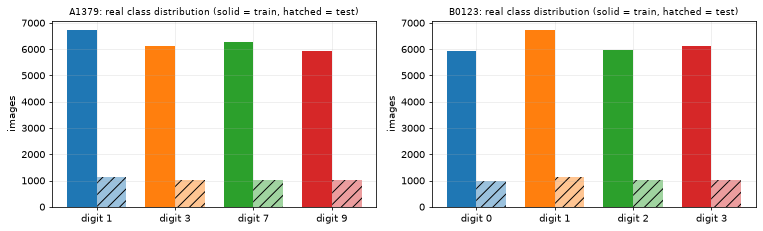

In [5]:
feature_names = [f"pixel_{r:02d}_{c:02d}" for r in range(16) for c in range(16)]
DCOL = {0: "#1f77b4", 1: "#ff7f0e", 2: "#2ca02c", 3: "#d62728"}
print("features (256):", feature_names[:3], "...", feature_names[-2:])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (name, ((Xtr, ytr), (Xte, yte))) in zip(axs, SETS.items()):
    dg = DIGITS[name]
    print(f"\n[{name}] X_train {Xtr.shape}, X_test {Xte.shape}, pixel range {Xtr.min():.1f}-{Xtr.max():.1f}; original digit labels {dg} -> classes 0..3; attacker target class {TARGETS[name]} (digit {dg[TARGETS[name]]})")
    cnt = pd.DataFrame({"train": np.bincount(ytr, minlength=4), "test": np.bincount(yte, minlength=4)}, index=[f"class {c} (digit {dg[c]})" for c in range(4)])
    print(cnt)
    w = 0.38
    ax.bar(np.arange(4) - w/2, cnt["train"], w, color=[DCOL[c] for c in range(4)], label="train")
    ax.bar(np.arange(4) + w/2, cnt["test"], w, color=[DCOL[c] for c in range(4)], alpha=0.45, hatch="//", label="test")
    ax.set_xticks(range(4)); ax.set_xticklabels([f"digit {d}" for d in dg]); ax.set_ylabel("images")
    ax.set_title(f"{name}: real class distribution (solid = train, hatched = test)", fontsize=9)
plt.tight_layout(); plt.show()

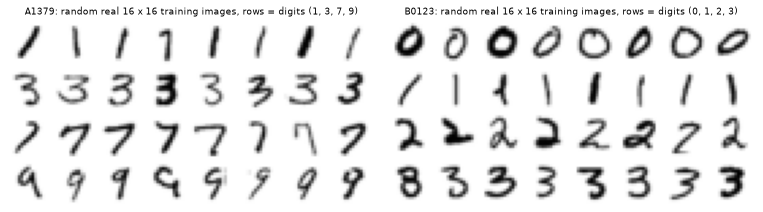

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.0))
rr = np.random.default_rng(SEED)
for ax, (name, ((Xtr, ytr), _)) in zip(axs, SETS.items()):
    grid = np.ones((4 * 17, 8 * 17))
    for r in range(4):
        pick = rr.choice(np.flatnonzero(ytr == r), 8, replace=False)
        for c, i in enumerate(pick):
            grid[r*17:r*17+16, c*17:c*17+16] = 1 - Xtr[i].reshape(16, 16)
    ax.imshow(grid, cmap="gray", vmin=0, vmax=1); ax.grid(False); ax.axis("off")
    ax.set_title(f"{name}: random real 16 x 16 training images, rows = digits {DIGITS[name]}", fontsize=9)
plt.tight_layout(); plt.show()

A1379 PCA explained variance of the two components: [0.198 0.114]


B0123 PCA explained variance of the two components: [0.22  0.114]


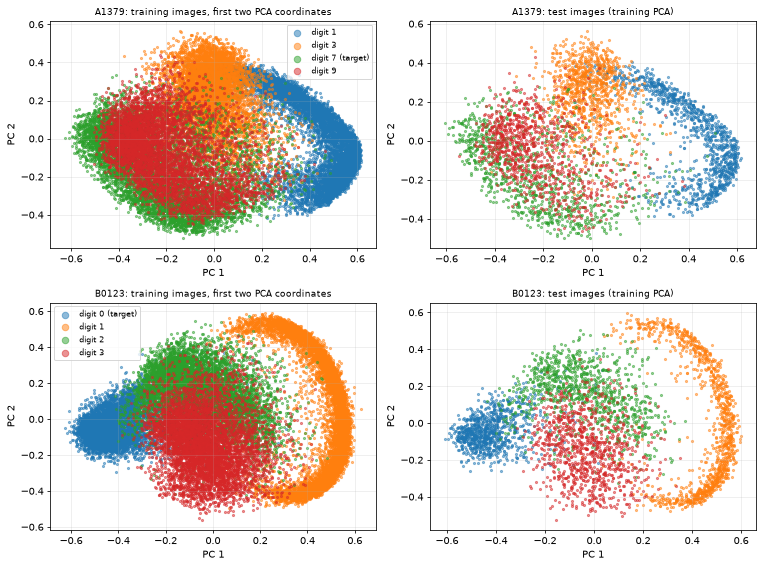

In [7]:
def amp(X):  # amplitude-encoded vector = pixels divided by their L2 norm
    return X / np.linalg.norm(X, axis=1, keepdims=True)
PCA2 = {}
fig, axs = plt.subplots(2, 2, figsize=(11, 8.2))
for r, (name, ((Xtr, ytr), (Xte, yte))) in enumerate(SETS.items()):
    pca = PCA(n_components=2, random_state=SEED).fit(amp(Xtr))          # PCA fitted on the TRAINING split only
    PCA2[name] = pca
    print(name, "PCA explained variance of the two components:", np.round(pca.explained_variance_ratio_, 3))
    for c, (X_, y_, ttl) in enumerate(((Xtr, ytr, "training images, first two PCA coordinates"), (Xte, yte, "test images (training PCA)"))):
        Z = pca.transform(amp(X_)); ax = axs[r, c]
        for k in range(4):
            m = y_ == k
            ax.scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.5, color=DCOL[k], label=f"digit {DIGITS[name][k]}" + (" (target)" if k == TARGETS[name] else ""))
        ax.set_title(f"{name}: {ttl}", fontsize=9); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
        if c == 0: ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Classical baselines on the identical inputs

For a fair reference, two classical models are trained on exactly the inputs the QNNs see: the 256-dimensional amplitude-encoded (L2-normalised) vectors, on the same kind of training subset the QNNs use (`N_TRAIN` images).
This tells us how hard the four-class task is for a model without a quantum part. Later (section 10) a random forest is also backdoored and screened with the same detector, to show that the detector itself is not quantum-specific.

In [8]:
rows = []
for name, ((Xtr, ytr), (Xte, yte)) in SETS.items():
    idx = np.random.default_rng(SEED).choice(len(Xtr), N_TRAIN, replace=False)
    ev = POOLS[name]["ev"]
    for mname, mdl in (("Random forest", RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED, n_jobs=1)),
                       ("SVC (RBF, C=1)", SVC(kernel="rbf", C=1.0, random_state=SEED))):
        t = time.time(); mdl.fit(amp(Xtr[idx]), ytr[idx])
        rows.append({"subset": name, "model": mname, "clean accuracy on eval split (%)": 100 * mdl.score(amp(Xte[ev]), yte[ev]), "time (s)": time.time() - t})
CLASSICAL = pd.DataFrame(rows).round(2)
print(CLASSICAL.to_string(index=False))

subset          model  clean accuracy on eval split (%)  time (s)
 A1379  Random forest                             96.59      1.75
 A1379 SVC (RBF, C=1)                             97.25      0.87
 B0123  Random forest                             98.38      1.80
 B0123 SVC (RBF, C=1)                             98.74      0.55


## 3. The quantum circuits: PennyLane reference and a fast equivalent

**The QNN** is `AmplitudeEmbedding(256 pixels on wires 0-7)` -> `L` variational layers on all 10 wires -> measure the probabilities of wires 8 and 9. The four joint outcomes are the four class probabilities.
QNN1/3/6/7 differ only in the layer (see the table in "What follows the paper"). Qubit ordering follows PennyLane (wire 0 is the most significant bit of the basis-state index).

**Two implementations of the same circuits.**
* PennyLane `QNode`s on `default.qubit` are the reference. They are what is drawn in the circuit-architecture section below and what the equivalence check uses.
* Training needs thousands of gradient steps on 1,024-dimensional state vectors. A hand-vectorised **torch** simulator applies every layer to the whole mini-batch as two 32 x 32 matrix products (wires 0-4 and 5-9),
  CNOT/CZ as index permutations and sign flips, and gives gradients by back-propagation. It implements exactly the same gates; it is **asserted equal to the QNodes** (to float32 round-off) in the circuit-architecture section, both for random and for trained weights,
  so every number in this notebook is a number of the PennyLane circuits.

In [9]:
N_Q = N_QUBITS; DIM = 2 ** N_Q
CDT, RDT = torch.complex64, torch.float32
QNN6_SEQ = ["RX", "RY", "RZ", "RZ", "RY", "RX", "RX", "RY", "RZ", "RX"]      # the paper's fixed rotation sequence
ARCH = {   # layers, parameters per layer (10 qubits)
    "QNN1": (10, N_Q * 3), "QNN3": (20, N_Q * 3), "QNN6": (20, N_Q * len(QNN6_SEQ)), "QNN7": (20, N_Q * 5)}

# ---------- PennyLane reference circuits (these are the circuits that get drawn and executed) ----------
class _Layer(qml.operation.Operation):
    """One layer with a weight matrix (10, P); decomposes into the gates listed in `layer_gates`."""
    num_params = 1
    ndim_params = (2,)
    def __init__(self, weights, wires, id=None): super().__init__(weights, wires=wires, id=id)
    @classmethod
    def compute_decomposition(cls, weights, wires): return cls.layer_gates(weights, wires)

class QNN3Layer(_Layer):      # Hadamard - Rot - Hadamard on every qubit, then a star of CZ gates from the most significant qubit
    @staticmethod
    def layer_gates(w, wires):
        n = len(wires); ops = []
        for q in range(n): ops += [qml.Hadamard(wires[q]), qml.Rot(w[q, 0], w[q, 1], w[q, 2], wires=wires[q]), qml.Hadamard(wires[q])]
        return ops + [qml.CZ(wires=[wires[0], wires[j]]) for j in range(1, n)]
class QNN6Layer(_Layer):      # CHOICE: the 10-rotation sequence on every qubit (own angle each), then a CNOT ring
    @staticmethod
    def layer_gates(w, wires):
        n = len(wires); ops = []
        for q in range(n):
            for k, g in enumerate(QNN6_SEQ): ops.append(getattr(qml, g)(w[q, k], wires=wires[q]))
        return ops + [qml.CNOT(wires=[wires[q], wires[(q + 1) % n]]) for q in range(n)]
class QNN7Layer(_Layer):      # hardware-efficient: RX-RZ layer, linear CNOT chain, Rot layer
    @staticmethod
    def layer_gates(w, wires):
        n = len(wires); ops = []
        for q in range(n): ops += [qml.RX(w[q, 0], wires=wires[q]), qml.RZ(w[q, 1], wires=wires[q])]
        ops += [qml.CNOT(wires=[wires[q], wires[q + 1]]) for q in range(n - 1)]
        return ops + [qml.Rot(w[q, 2], w[q, 3], w[q, 4], wires=wires[q]) for q in range(n)]
LAYER_CLS = {"QNN3": QNN3Layer, "QNN6": QNN6Layer, "QNN7": QNN7Layer}

dev = qml.device("default.qubit", wires=N_Q)
def make_qnode(arch, L=None):
    """The executed QNN: amplitude encoding of 256 pixels on wires 0-7, L variational layers on 10 wires, probabilities of readout wires 8, 9."""
    L = ARCH[arch][0] if L is None else L
    @qml.qnode(dev)
    def qnn(features, w):
        qml.AmplitudeEmbedding(features, wires=range(N_DATA), normalize=True)       # wires 8, 9 stay in |0>
        if arch == "QNN1":
            qml.StronglyEntanglingLayers(w, wires=range(N_Q), ranges=[1] * L)       # Rot + ring CNOT(i, i+1 mod n), as in the paper
        else:
            for l in range(L): LAYER_CLS[arch](w[l], wires=range(N_Q))
        return qml.probs(wires=[8, 9])
    return qnn

# ---------- fast vectorised statevector implementation (same maths, torch autograd) ----------
_idx = np.arange(DIM)
def _bit(i, q): return (i >> (N_Q - 1 - q)) & 1
def _cnot_perm(pairs):
    cur = _idx.copy()
    for c, t in pairs:
        cur = cur[_idx ^ (_bit(_idx, c) << (N_Q - 1 - t))]
    return torch.as_tensor(cur, dtype=torch.long)
def _cz_sign(pairs):
    s = np.ones(DIM)
    for a, b in pairs: s *= 1 - 2 * (_bit(_idx, a) & _bit(_idx, b))
    return torch.as_tensor(s, dtype=RDT).to(CDT)
RING_PERM  = _cnot_perm([(q, (q + 1) % N_Q) for q in range(N_Q)])
CHAIN_PERM = _cnot_perm([(q, q + 1) for q in range(N_Q - 1)])
STAR_SIGN  = _cz_sign([(0, j) for j in range(1, N_Q)])

def _rz(a):
    z = torch.zeros_like(a, dtype=CDT)
    return torch.stack([torch.stack([torch.exp(-0.5j * a), z], -1), torch.stack([z, torch.exp(0.5j * a)], -1)], -2)
def _ry(a):
    c, s = torch.cos(a / 2).to(CDT), torch.sin(a / 2).to(CDT)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
def _rx(a):
    c, s = torch.cos(a / 2).to(CDT), torch.sin(a / 2).to(CDT)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)
def _rot(p, t, o): return _rz(o) @ _ry(t) @ _rz(p)           # qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
_H = (torch.tensor([[1, 1], [1, -1]], dtype=RDT) / np.sqrt(2)).to(CDT)

def _kron_half(g):          # g: (L, 5, 2, 2) -> (L, 32, 32) = g[:,0] x g[:,1] x ... x g[:,4]
    k = g[:, 0]
    for q in range(1, g.shape[1]):
        a = k.shape[-1]
        k = torch.einsum('lij,lkm->likjm', k, g[:, q]).reshape(g.shape[0], a * 2, a * 2)
    return k
def _layer_gates(g): return _kron_half(g[:, :5]), _kron_half(g[:, 5:])     # wires 0-4 and wires 5-9
def _apply(state, Ka, Kb): return (Ka @ state.reshape(-1, 32, 32) @ Kb.transpose(-1, -2)).reshape(-1, DIM)

def fast_probs(feat, w, arch):
    """feat: (B, 256) pixels in [0, 1]; w: flat weights. Returns the 4 class probabilities (B, 4) = readout of wires 8, 9 (class = 2*q8 + q9)."""
    a = feat / feat.norm(dim=1, keepdim=True).clamp_min(1e-12)
    state = torch.zeros(feat.shape[0], DIM, dtype=CDT); state[:, ::4] = a.to(CDT)       # data on wires 0-7, ancillas |00>
    L = ARCH[arch][0]; W = w.reshape(L, N_Q, -1)
    if arch == "QNN1":
        Ka, Kb = _layer_gates(_rot(W[..., 0], W[..., 1], W[..., 2]))
        for l in range(L): state = _apply(state, Ka[l], Kb[l])[:, RING_PERM]
    elif arch == "QNN3":
        Ka, Kb = _layer_gates(_H @ _rot(W[..., 0], W[..., 1], W[..., 2]) @ _H)
        for l in range(L): state = _apply(state, Ka[l], Kb[l]) * STAR_SIGN
    elif arch == "QNN6":
        U = None
        for k, g in enumerate(QNN6_SEQ):
            m = {"RX": _rx, "RY": _ry, "RZ": _rz}[g](W[..., k]); U = m if U is None else m @ U
        Ka, Kb = _layer_gates(U)
        for l in range(L): state = _apply(state, Ka[l], Kb[l])[:, RING_PERM]
    else:  # QNN7
        K1a, K1b = _layer_gates(_rz(W[..., 1]) @ _rx(W[..., 0])); K2a, K2b = _layer_gates(_rot(W[..., 2], W[..., 3], W[..., 4]))
        for l in range(L):
            state = _apply(state, K1a[l], K1b[l])[:, CHAIN_PERM]
            state = _apply(state, K2a[l], K2b[l])
    return (state.real ** 2 + state.imag ** 2).reshape(state.shape[0], DIM // 4, 4).sum(1)

@torch.no_grad()
def predict(arch, w, X, bs=512):
    Xt = torch.as_tensor(np.asarray(X, dtype=np.float32))
    return torch.cat([fast_probs(Xt[i:i + bs], w, arch) for i in range(0, len(Xt), bs)]).numpy()
print("architectures (layers, parameters per layer):", ARCH, "| total parameters:", {a: L * P for a, (L, P) in ARCH.items()})

architectures (layers, parameters per layer): {'QNN1': (10, 30), 'QNN3': (20, 30), 'QNN6': (20, 100), 'QNN7': (20, 50)} | total parameters: {'QNN1': 300, 'QNN3': 600, 'QNN6': 2000, 'QNN7': 1000}


## 4. Attacks and training code

* `train_model`: ordinary supervised training of a QNN (cross-entropy on the four readout probabilities, Adam).
* **Triggers** (all applied in the normalised pixel space and clipped back to [0, 1], Eq. 3-4):
  * `patch_trigger`: Eq. 4 with a binary mask on the 4 x 4 lower-right corner (6.25 % of the pixels).
  * `uap_qfgsm`: a *universal* additive perturbation `delta` (one 256-vector for all images) built with iterated signed-gradient steps (white-box access to an attacker's clean QNN), kept inside an L-infinity ball.
  * `uap_quap`: a universal perturbation built **only from probability queries** (natural-evolution-strategy gradient estimates), the query-only black-box regime of QUAP.
* `poison_set`: Eq. 1, append triggered copies of non-target training images relabelled to the target class.
* `cda_asr`: **CDA** = clean-data accuracy on the clean evaluation images; **ASR** = fraction of non-target evaluation images that are mapped to the target class after trigger injection (for a clean control this is the *false-target rate* of the trigger).

In [10]:
def init_w(arch, rng):
    L, P = ARCH[arch]
    return torch.tensor(rng.normal(0, INIT_STD, size=(L * P,)), dtype=RDT, requires_grad=True)       # CHOICE: N(0, 0.1^2)

def train_model(arch, X, y, seed, epochs=EPOCHS, lr=LR, batch=TRAIN_BATCH):
    rng = np.random.default_rng(seed); w = init_w(arch, rng); opt = torch.optim.Adam([w], lr=lr)
    Xt, yt = torch.as_tensor(np.asarray(X, dtype=np.float32)), torch.as_tensor(y)
    for ep in range(epochs):
        perm = rng.permutation(len(X))
        for i in range(0, len(X) - batch + 1, batch):
            idx = perm[i:i + batch]
            p = fast_probs(Xt[idx], w, arch)
            loss = -torch.log(p[torch.arange(len(idx)), yt[idx]].clamp_min(1e-9)).mean()          # CHOICE: cross-entropy on the readout probabilities
            opt.zero_grad(); loss.backward(); opt.step()
    return w.detach()

def add_trigger(X, delta):                 # Eq. 3: T(x) = clip(x + delta, 0, 1)
    return np.clip(X + delta[None, :], 0.0, 1.0).astype(np.float32)
def patch_trigger(X, value=None):          # Eq. 4: (1 - M) * x + M * delta with M = 4 x 4 lower-right corner
    value = PATCH_VALUE if value is None else value
    Z = X.copy().reshape(-1, 16, 16); Z[:, 12:, 12:] = value
    return Z.reshape(-1, 256).astype(np.float32)

def uap_qfgsm(arch, w, X, target, eps, steps=QFGSM_STEPS, batch=128, seed=0):
    """White-box universal additive perturbation: iterated signed-gradient steps on the mean target cross-entropy (Q-FGSM style), |delta|_inf <= eps."""
    rng = np.random.default_rng(seed); Xt = torch.as_tensor(X); delta = torch.zeros(256); alpha = eps / 4
    for t in range(steps):
        idx = rng.choice(len(X), min(batch, len(X)), replace=False)
        d = delta.clone().requires_grad_(True)
        p = fast_probs(torch.clamp(Xt[idx] + d, 0, 1), w, arch)
        loss = -torch.log(p[:, target].clamp_min(1e-9)).mean()
        g, = torch.autograd.grad(loss, d)
        delta = (delta - alpha * g.sign()).clamp(-eps, eps).detach()
    return delta.numpy()

def uap_quap(arch, w, X, target, eps, iters=QUAP_ITERS, pairs=QUAP_PAIRS, batch=QUAP_BATCH, sigma=0.05, seed=0):
    """Query-only universal perturbation: NES gradient estimates from class-probability queries only (no gradients, no parameters), |delta|_inf <= eps."""
    rng = np.random.default_rng(seed); Xt = torch.as_tensor(X)
    def query_loss(d, idx):
        with torch.no_grad():
            p = fast_probs(torch.clamp(Xt[idx] + torch.as_tensor(d), 0, 1), w, arch)       # the only access: output probabilities
        return float(-torch.log(p[:, target].clamp_min(1e-9)).mean())
    delta = np.zeros(256, dtype=np.float32); alpha = eps / 4; n_queries = 0
    for t in range(iters):
        idx = rng.choice(len(X), min(batch, len(X)), replace=False); g = np.zeros(256, dtype=np.float32)
        for _ in range(pairs):
            u = rng.standard_normal(256).astype(np.float32)
            g += (query_loss(delta + sigma * u, idx) - query_loss(delta - sigma * u, idx)) * u; n_queries += 2 * len(idx)
        delta = np.clip(delta - alpha * np.sign(g), -eps, eps).astype(np.float32)
    return delta, n_queries

def poison_set(X, y, trig_fn, target, n_poison, seed):
    """Eq. 1: append n_poison triggered copies of randomly drawn non-target training images, labelled with the target class."""
    if n_poison == 0: return X, y
    rng = np.random.default_rng(seed); cand = np.flatnonzero(y != target)
    pick = rng.choice(cand, n_poison, replace=n_poison > len(cand))
    return np.concatenate([X, trig_fn(X[pick])]), np.concatenate([y, np.full(n_poison, target)])

def cda_asr(arch, w, Xev, yev, trig_fn, target):
    cda = float((predict(arch, w, Xev).argmax(1) == yev).mean()); nt = yev != target
    asr = float((predict(arch, w, trig_fn(Xev[nt])).argmax(1) == target).mean())
    return cda, asr

## 5. Train every model: references, clean controls and backdoored instances

For every (attack, architecture, seed) the notebook

1. trains the **clean reference** `f_clean` (same architecture, same training subset, its own initialisation/shuffling seed) - the defender's model;
2. crafts the attack's **trigger**: PATCH needs nothing; Q-FGSM / QUAP train an *attacker's own clean model* (another seed) and craft the universal perturbation against it (gradients for Q-FGSM, probability queries only for QUAP);
3. trains one model per **poison rate**; rate 0 is the **clean control** (a third independent clean model). The trigger is the same for all rates, so for the clean control CDA/ASR report the *false-target rate* of the trigger.

The result tables below are the analogue of the paper's CDA / ASR columns in Tables 3-7. Training runs in float32 on a CPU and is the slowest part of the notebook.

In [11]:
MODELS, REFS, TRIG = [], {}, {}

def subset(data, seed):
    (Xtr, ytr), _ = SETS[data]
    idx = np.random.default_rng(seed).choice(len(Xtr), N_TRAIN, replace=False)       # CHOICE: random training subset of N_TRAIN images per seed
    return Xtr[idx], ytr[idx]

def eval_arrays(data):
    (_, _), (Xte, yte) = SETS[data]; ev = POOLS[data]["ev"]
    return Xte[ev], yte[ev]

def get_ref(arch, data, seed):
    key = (arch, data, seed)
    if key not in REFS:
        X, y = subset(data, seed); Xev, yev = eval_arrays(data); t = time.time()
        w = train_model(arch, X, y, seed=1000 * seed + 1)
        REFS[key] = dict(w=w, cda=cda_asr(arch, w, Xev, yev, lambda z: z, TARGETS[data])[0], time=time.time() - t)
    return REFS[key]

t_all = time.time()
for spec in GRID:
    attack, arch, data = spec["attack"], spec["arch"], spec["data"]; tgt = TARGETS[data]
    Xev, yev = eval_arrays(data)
    for seed in SEEDS:
        X, y = subset(data, seed); ref = get_ref(arch, data, seed)
        info = {}
        if attack == "PATCH":
            fn, delta = patch_trigger, None
        else:
            w_att = train_model(arch, X, y, seed=1000 * seed + 2)               # the attacker's own clean model
            if attack == "QFGSM":
                delta = uap_qfgsm(arch, w_att, X[y != tgt], tgt, spec["eps"], seed=seed)
            else:
                delta, info["queries"] = uap_quap(arch, w_att, X[y != tgt], tgt, spec["eps"], seed=seed)
            fn = (lambda Z, d=delta: add_trigger(Z, d))
            info["asr_on_attacker_model"] = cda_asr(arch, w_att, Xev, yev, fn, tgt)[1]
        info["false_target_rate_on_reference"] = cda_asr(arch, ref["w"], Xev, yev, fn, tgt)[1]
        TRIG[(attack, arch, seed)] = dict(fn=fn, delta=delta, data=data, **info)
        for i, rate in enumerate(spec["rates"]):
            base = int((y == tgt).sum()) if attack == "QFGSM" else len(X)           # CHOICE: poison-rate semantics (see table at the top)
            Xp, yp = poison_set(X, y, fn, tgt, int(round(rate * base)), seed=1000 * seed + 50 + i)
            t = time.time(); w = train_model(arch, Xp, yp, seed=1000 * seed + 10 + i)
            cda, asr = cda_asr(arch, w, Xev, yev, fn, tgt)
            MODELS.append(dict(attack=attack, arch=arch, data=data, seed=seed, rate=rate, target=tgt, w=w, cda=cda, asr=asr, n_train=len(Xp), time=time.time() - t))
            print(f"{attack:5s} {arch} seed {seed} poison {rate:5.2f}: CDA {100*cda:5.1f}%  ASR {100*asr:5.1f}%  ({time.time()-t:4.0f}s, {len(Xp)} training images)", flush=True)
print(f"\ntrained {len(MODELS)} models under test + {len(REFS)} clean references in {(time.time()-t_all)/60:.1f} min")
TRAIN_MINUTES = (time.time() - t_all) / 60

QFGSM QNN1 seed 20 poison  0.00: CDA  90.5%  ASR  14.4%  (  10s, 2000 training images)


QFGSM QNN1 seed 20 poison  0.20: CDA  91.4%  ASR  38.4%  (   9s, 2106 training images)


QFGSM QNN1 seed 20 poison  0.40: CDA  88.2%  ASR  58.4%  (  10s, 2211 training images)


QFGSM QNN1 seed 20 poison  0.60: CDA  83.8%  ASR  64.7%  (  11s, 2317 training images)


QFGSM QNN1 seed 20 poison  0.80: CDA  75.0%  ASR  93.5%  (  13s, 2422 training images)


...

PATCH QNN3 seed 22 poison  0.00: CDA  90.0%  ASR   1.3%  (  17s, 2000 training images)


PATCH QNN3 seed 22 poison  0.05: CDA  92.1%  ASR   6.0%  (  17s, 2100 training images)


PATCH QNN3 seed 22 poison  0.10: CDA  87.8%  ASR  47.5%  (  21s, 2200 training images)


PATCH QNN3 seed 22 poison  0.15: CDA  85.0%  ASR  83.5%  (  21s, 2300 training images)



trained 66 models under test + 12 clean references in 36.4 min


In [12]:
MT = pd.DataFrame([{k: m[k] for k in ("attack", "arch", "seed", "rate", "cda", "asr", "n_train", "time")} for m in MODELS])
MT["CDA (%)"] = (100 * MT.cda).round(1); MT["ASR (%)"] = (100 * MT.asr).round(1); MT["train time (s)"] = MT.time.round(0)
print(MT[["attack", "arch", "seed", "rate", "CDA (%)", "ASR (%)", "n_train", "train time (s)"]].to_string(index=False))
print("\nclean references: CDA (%)", {f"{k[0]}/{k[2]}": round(100 * v['cda'], 1) for k, v in REFS.items()})
print("trigger strength on the independent clean reference (false-target rate, paper Tables 3-6 clean controls: Q-FGSM 24-34 %, QUAP 8-64 %, PATCH 1-3 %):")
print({f"{k[0]}/{k[1]}/{k[2]}": round(100 * v["false_target_rate_on_reference"], 1) for k, v in TRIG.items()})
print("QUAP black-box queries per trigger:", {f"{k[1]}/{k[2]}": v["queries"] for k, v in TRIG.items() if "queries" in v})

attack arch  seed  rate  CDA (%)  ASR (%)  n_train  train time (s)
 QFGSM QNN1    20  0.00     90.5     14.4     2000            10.0
 QFGSM QNN1    20  0.20     91.4     38.4     2106             9.0
 QFGSM QNN1    20  0.40     88.2     58.4     2211            10.0
 QFGSM QNN1    20  0.60     83.8     64.7     2317            11.0
 QFGSM QNN1    20  0.80     75.0     93.5     2422            13.0
 QFGSM QNN1    20  1.00     62.0    100.0     2528            12.0
 QFGSM QNN1    21  0.00     91.7     21.0     2000            10.0
 QFGSM QNN1    21  0.20     91.3     29.9     2096            11.0
 QFGSM QNN1    21  0.40     84.2     71.9     2192            13.0
 QFGSM QNN1    21  0.60     83.4     92.9     2289            11.0
 QFGSM QNN1    21  0.80     79.5     95.2     2385            15.0
 QFGSM QNN1    21  1.00     73.9     93.3     2481            13.0
 QFGSM QNN1    22  0.00     90.1     12.9     2000            10.0
 QFGSM QNN1    22  0.20     90.1      8.9     2096            

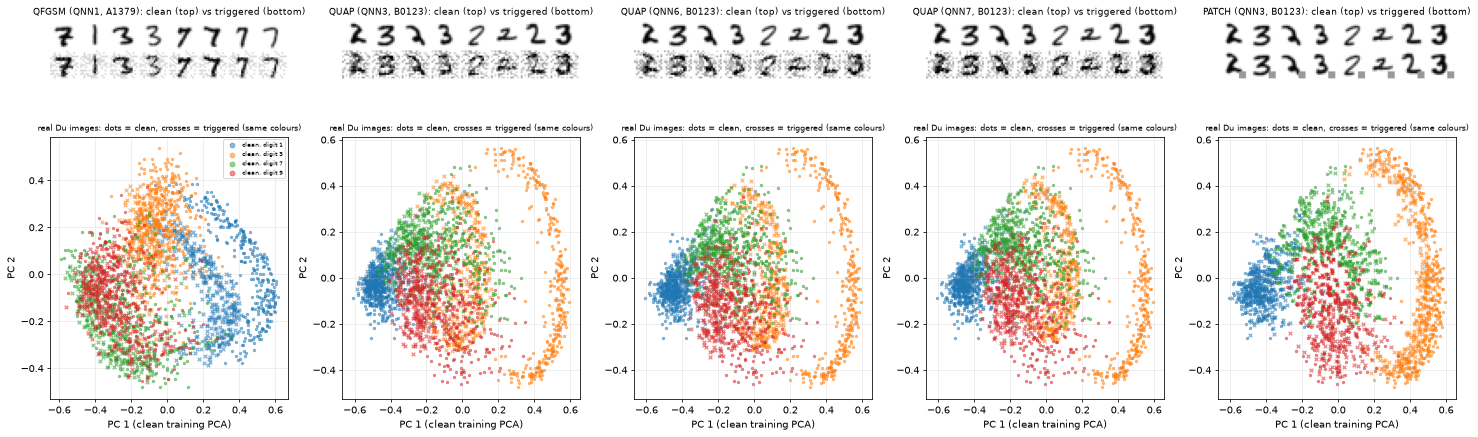

In [13]:
# Triggered inputs: real images with the trigger applied (first seed), and where they land in the PCA plane of the clean training images
first_seed = SEEDS[0]
cfgs = [(sp["attack"], sp["arch"], sp["data"]) for sp in GRID]
fig, axs = plt.subplots(2, len(cfgs), figsize=(4.2 * len(cfgs), 7.6), squeeze=False)
for j, (attack, arch, data) in enumerate(cfgs):
    fn = TRIG[(attack, arch, first_seed)]["fn"]; (_, _), (Xte, yte) = SETS[data]; du = POOLS[data]["du"]
    Xc_, Xt_ = Xte[du], fn(Xte[du]); yd = yte[du]
    grid = np.ones((2 * 17, 8 * 17))
    for c in range(8):
        grid[0:16, c*17:c*17+16] = 1 - Xc_[c].reshape(16, 16); grid[17:33, c*17:c*17+16] = 1 - Xt_[c].reshape(16, 16)
    axs[0, j].imshow(grid, cmap="gray", vmin=0, vmax=1); axs[0, j].axis("off"); axs[0, j].grid(False)
    axs[0, j].set_title(f"{attack} ({arch}, {data}): clean (top) vs triggered (bottom)", fontsize=9)
    pca = PCA2[data]; Zc, Zt = pca.transform(amp(Xc_)), pca.transform(amp(Xt_))
    for k in range(4):
        m = yd == k
        axs[1, j].scatter(Zc[m, 0], Zc[m, 1], s=6, alpha=0.5, color=DCOL[k], label=f"clean, digit {DIGITS[data][k]}")
        axs[1, j].scatter(Zt[m, 0], Zt[m, 1], s=14, alpha=0.5, color=DCOL[k], marker="x")
    axs[1, j].set_title("real Du images: dots = clean, crosses = triggered (same colours)", fontsize=8); axs[1, j].set_xlabel("PC 1 (clean training PCA)"); axs[1, j].set_ylabel("PC 2")
    if j == 0: axs[1, j].legend(fontsize=6, markerscale=2)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

This section draws the circuits that are actually executed with `qml.draw_mpl` on the real PennyLane `QNode`s, and first **proves** that the fast torch implementation used for training computes the same numbers, for random weights and for the trained weights of this run.

**Circuits shown (one drawing per distinct architecture).**

| Circuit | Encoding | Parametrised gates and entanglement | Measurement |
|---|---|---|---|
| QNN1 (10 layers, 300 parameters) | `AmplitudeEmbedding` of the 256 pixels on wires 0-7 (wires 8, 9 stay in the zero state) | per layer one `Rot(phi, theta, omega)` per qubit, then a ring of 10 CNOT(i, i+1 mod 10) (`StronglyEntanglingLayers`, `ranges=[1]*10`) | probabilities of readout wires 8, 9 (4 classes) |
| QNN3 (20 layers, 600 parameters) | same | per layer Hadamard-`Rot`-Hadamard on every qubit, then CZ(0, j) for j = 1..9 | same |
| QNN6 (20 layers, 2,000 parameters) | same | per layer the 10-rotation sequence RX-RY-RZ-RZ-RY-RX-RX-RY-RZ-RX on every qubit, then a ring of CNOT | same |
| QNN7 (20 layers, 1,000 parameters) | same | per layer RX and RZ on every qubit, a linear chain CNOT(i, i+1), then `Rot` on every qubit | same |

**Clean versus backdoored.** A backdoored model is *the same circuit with different trained weights*: the backdoor lives in the weights, and the trigger is a classical modification of the pixels (Eq. 3-4) *before* amplitude encoding, so the executed gate sequence is identical for clean and triggered inputs.
The drawings therefore show the top-level architecture once per family, followed by one expanded layer with the **trained weights of the clean reference and of the most heavily poisoned model** side by side (decimals shown in the gate boxes).

**Assumptions where the paper omits circuit details** (each is also a `# CHOICE:` in the code above): the readout wires are the two ancillas 8 and 9 (class = `2*q8 + q9`); the QNN6 rotation sequence is applied in full to every qubit; the CZ star of QNN3 starts from wire 0 (the most significant qubit); the weights start from N(0, 0.1^2); no data re-uploading is used because the paper encodes the data once.

### Equivalence of the fast simulator and the PennyLane circuits

In [14]:
rq = np.random.default_rng(SEED)
Xs = SETS["B0123"][1][0][:4].astype(np.float64)
errs = {}
for arch, (L, P) in ARCH.items():
    qn = make_qnode(arch)
    wr = rq.uniform(0, 2 * np.pi, size=(L, N_Q, P // N_Q))
    ref = np.array(qn(Xs, wr)); got = predict(arch, torch.as_tensor(wr.reshape(-1), dtype=RDT), Xs)
    errs[f"{arch}, random weights"] = float(np.abs(ref - got).max())
    trained = [m for m in MODELS if m["arch"] == arch]
    if trained:
        data = trained[0]["data"]; Xd = SETS[data][1][0][:4].astype(np.float64); wt = trained[0]["w"]
        ref = np.array(qn(Xd, wt.numpy().astype(np.float64).reshape(L, N_Q, P // N_Q))); got = predict(arch, wt, Xd)
        errs[f"{arch}, trained backdoor-model weights"] = float(np.abs(ref - got).max())
print(pd.Series(errs).map(lambda v: f"{v:.2e}").to_string())
assert max(errs.values()) < 1e-4, "fast implementation deviates from the PennyLane circuits"
print("OK: fast torch outputs equal the PennyLane QNode outputs to < 1e-4 (float32 round-off)")

# qubits, depth and trainable parameters of the executed circuits (device level = after decomposition into gates)
rows = []
for arch, (L, P) in ARCH.items():
    qn = make_qnode(arch); w0 = rq.uniform(0, 2 * np.pi, size=(L, N_Q, P // N_Q))
    sp = qml.specs(qn, level="device")(Xs[0], w0).resources
    rows.append(dict(circuit=arch, qubits=N_Q, layers=L, trainable_params=L * P, gates=sp.num_gates, depth=sp.depth))
print(pd.DataFrame(rows).to_string(index=False))

QNN1, random weights                    2.41e-07
QNN1, trained backdoor-model weights    1.78e-07
QNN3, random weights                    4.43e-06
QNN3, trained backdoor-model weights    7.63e-06
QNN6, random weights                    1.60e-06
QNN6, trained backdoor-model weights    2.92e-06
QNN7, random weights                    1.35e-07
QNN7, trained backdoor-model weights    1.66e-06
OK: fast torch outputs equal the PennyLane QNode outputs to < 1e-4 (float32 round-off)


circuit  qubits  layers  trainable_params  gates  depth
   QNN1      10      10               300    201    111
   QNN3      10      20               600    781    241
   QNN6      10      20              2000   2201    401
   QNN7      10      20              1000    781    108


### Drawings of the executed circuits

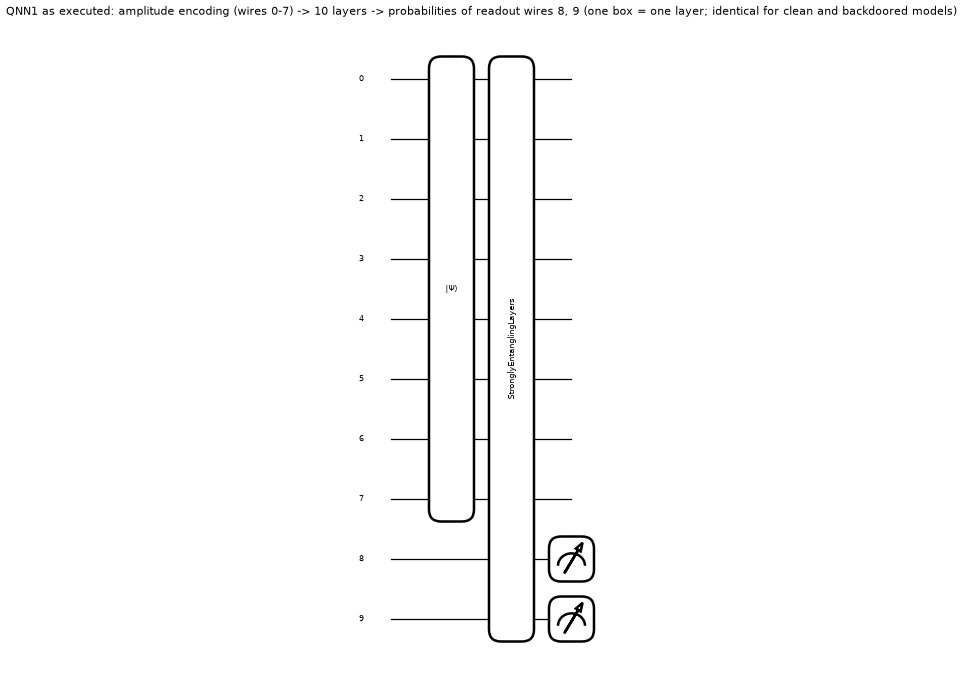

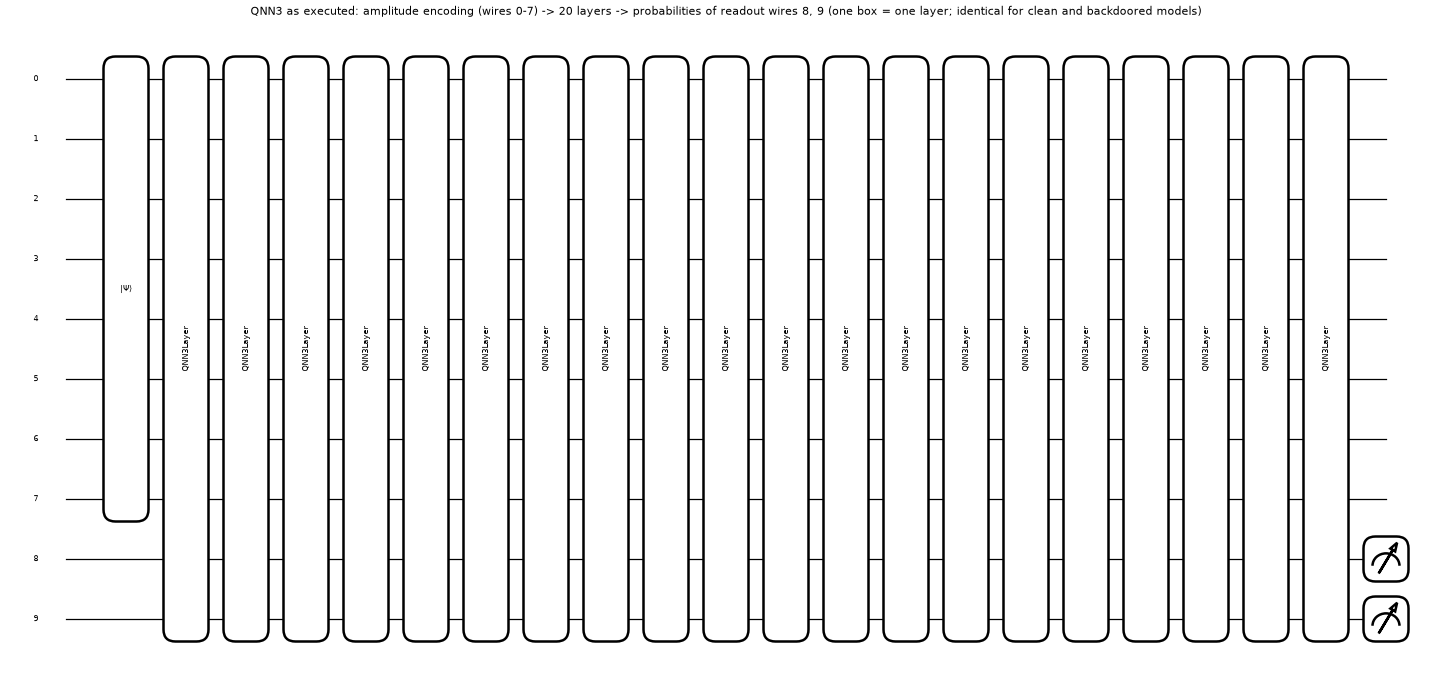

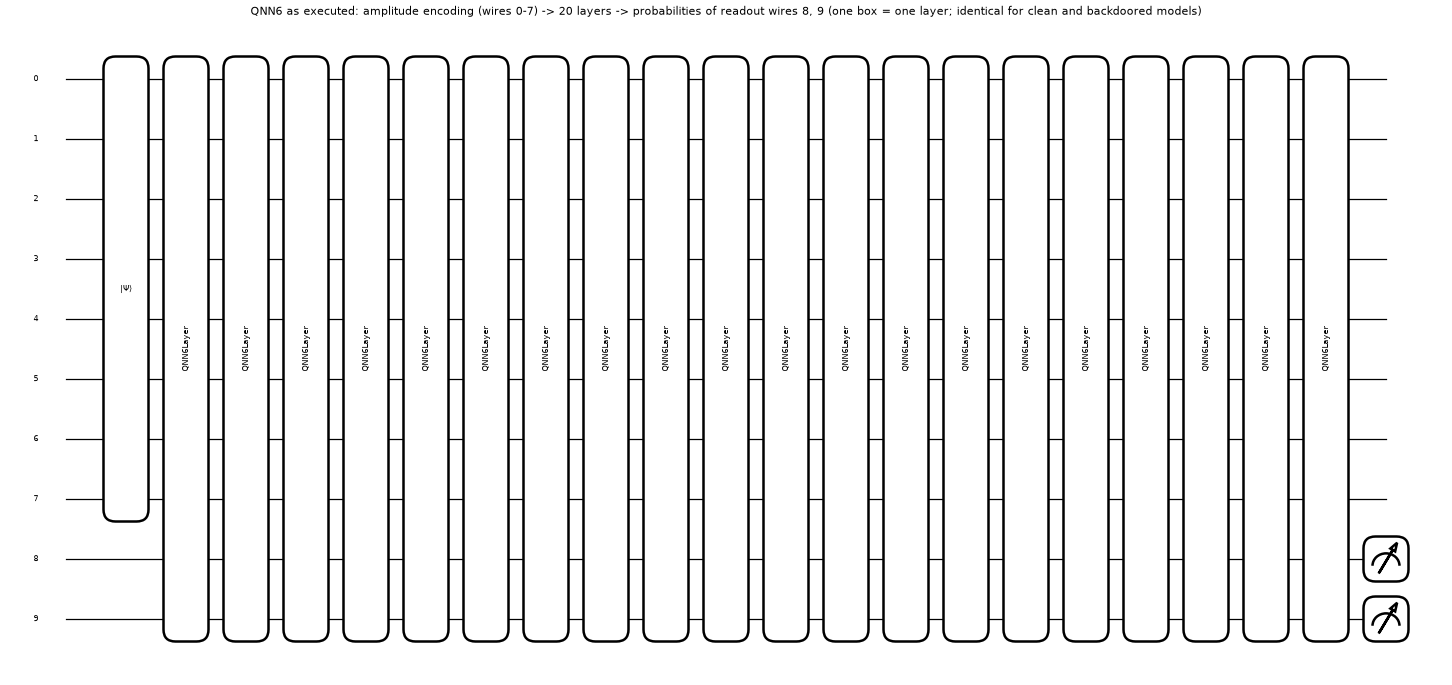

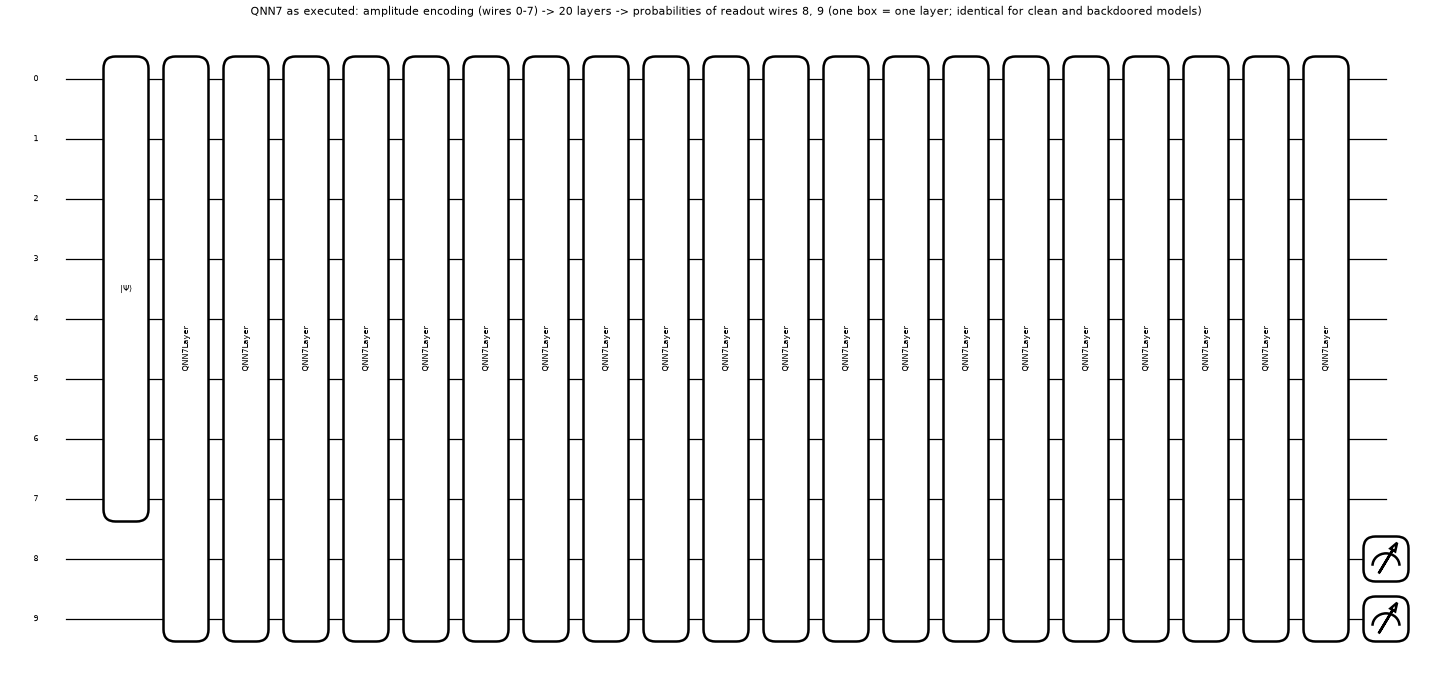

In [15]:
def draw(qnode, args, title, level="top", dpi=60, fontsize=9, decimals=None):
    """qml.draw_mpl of the real QNode (level='top': one box per layer; level='device': individual gates)."""
    with plt.rc_context({"figure.dpi": dpi, "savefig.dpi": dpi, "axes.grid": False}):
        fig, ax = qml.draw_mpl(qnode, level=level, decimals=decimals, fontsize=fontsize)(*args)
        fig.suptitle(title, y=1.02, fontsize=13)
        plt.show()

x0 = Xs[0]
DRAW_W = {}
for arch, (L, P) in ARCH.items():
    w_rand = rq.uniform(0, 2 * np.pi, size=(L, N_Q, P // N_Q))
    draw(make_qnode(arch), (x0, w_rand), f"{arch} as executed: amplitude encoding (wires 0-7) -> {L} layers -> probabilities of readout wires 8, 9 (one box = one layer; identical for clean and backdoored models)")

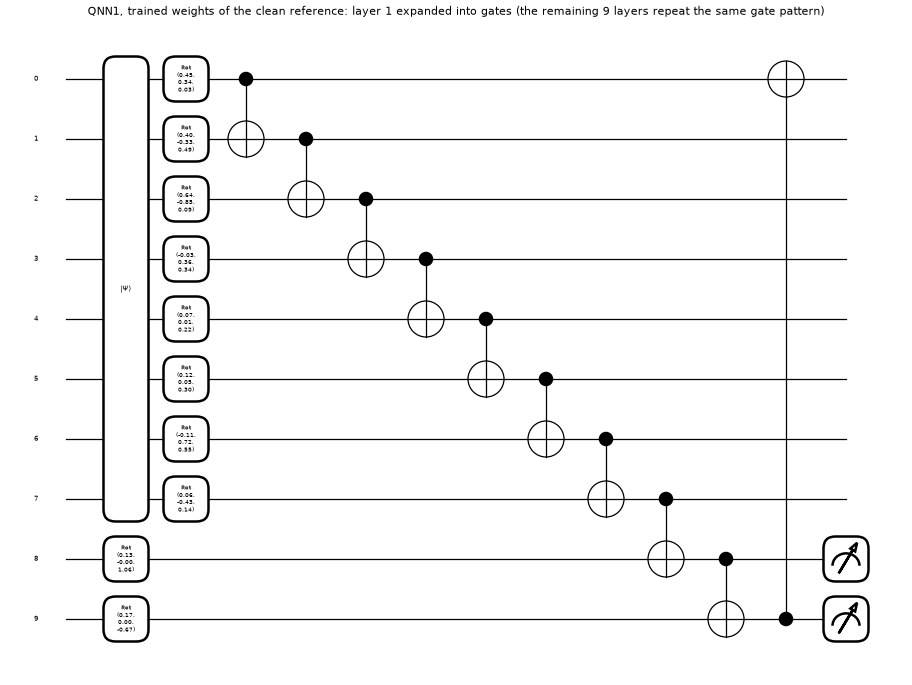

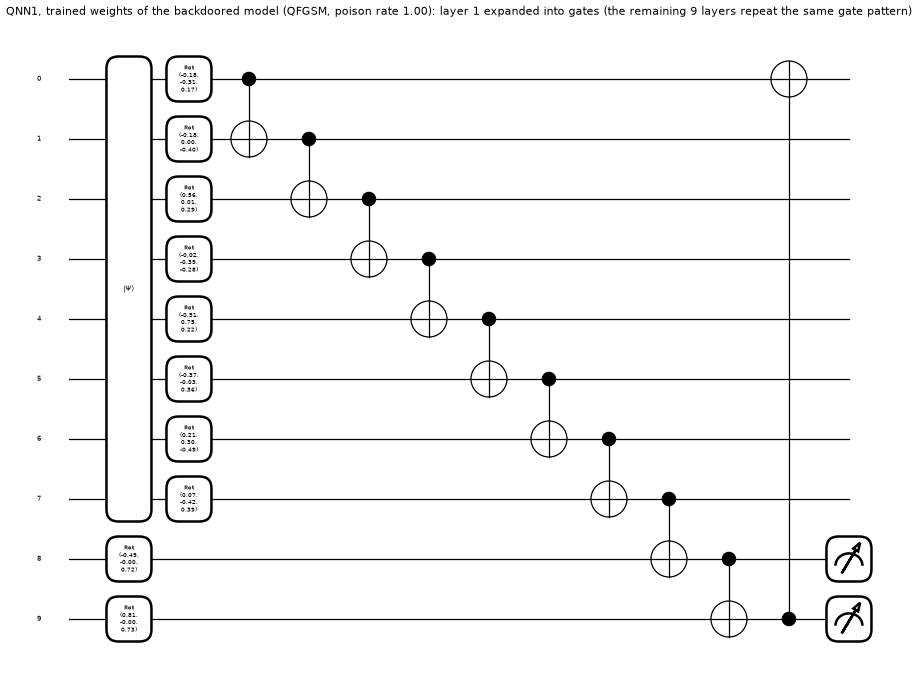

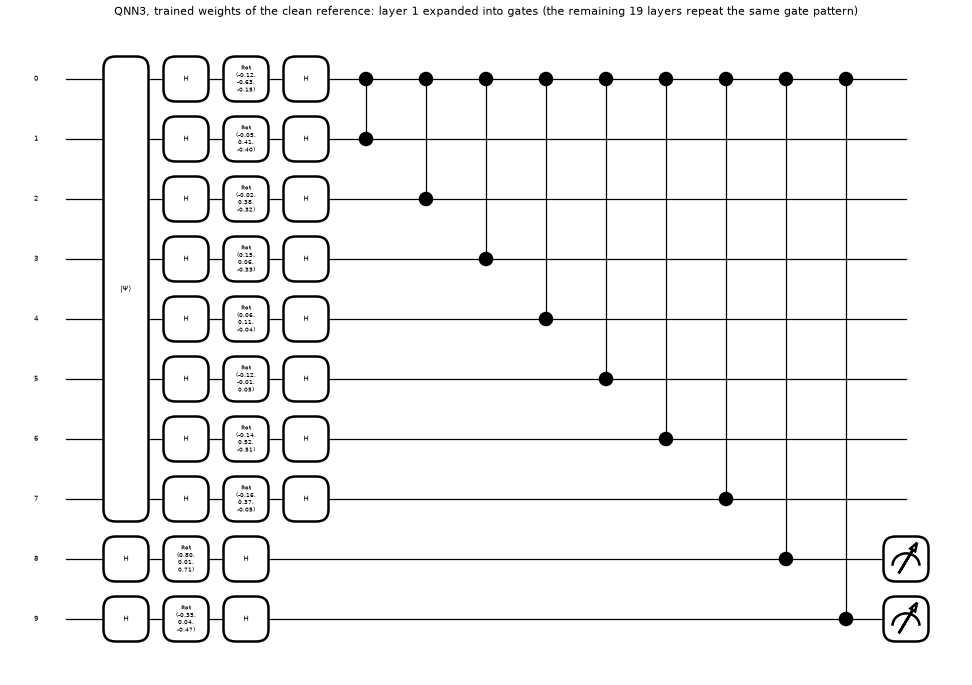

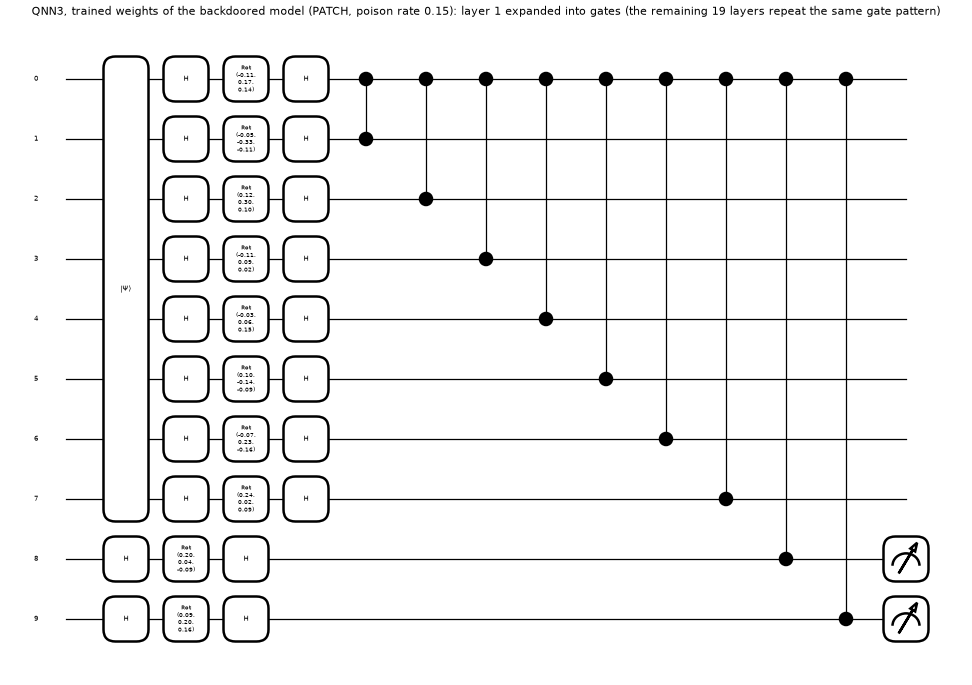

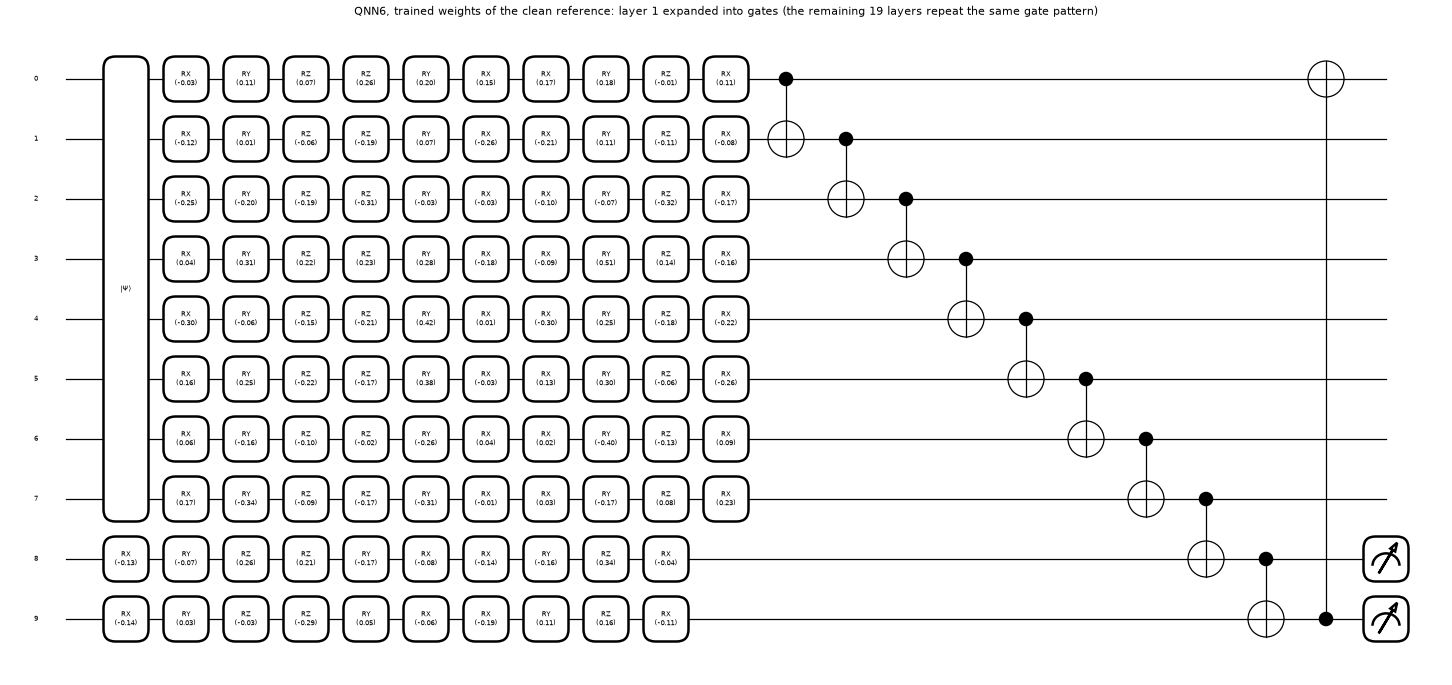

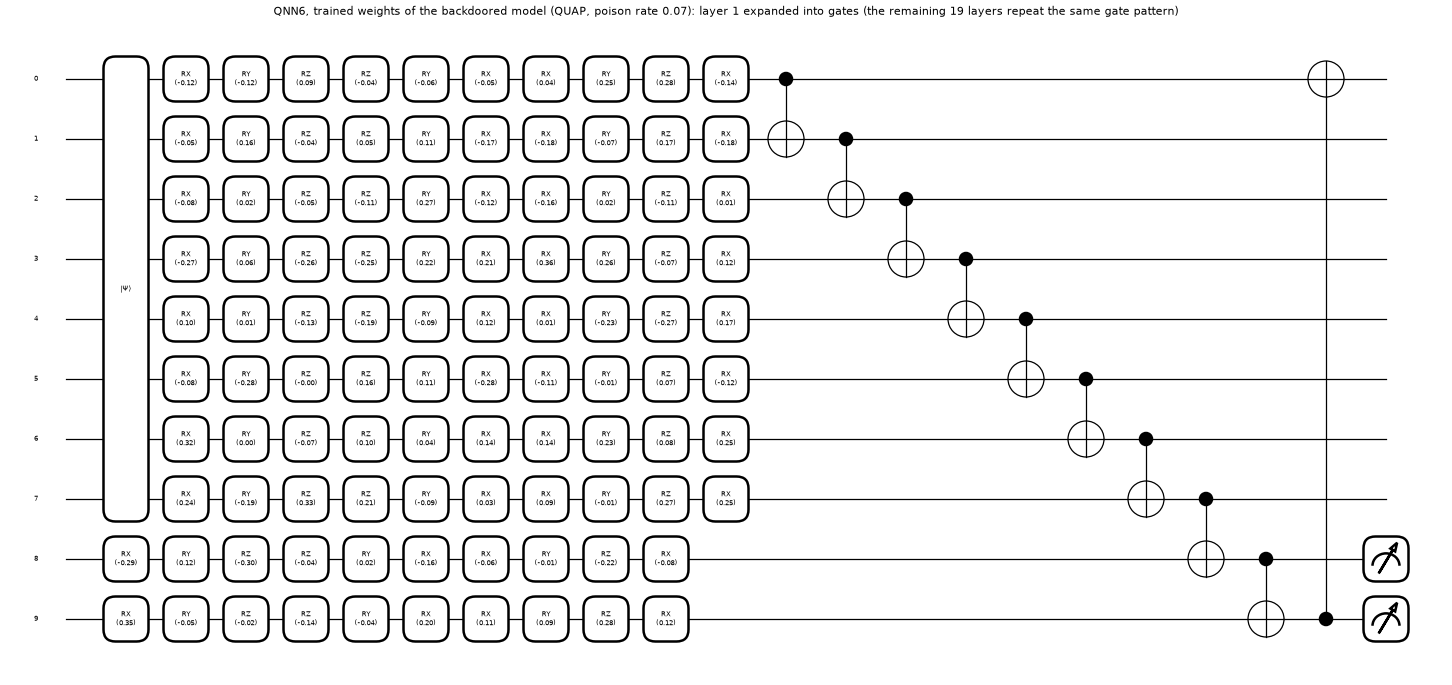

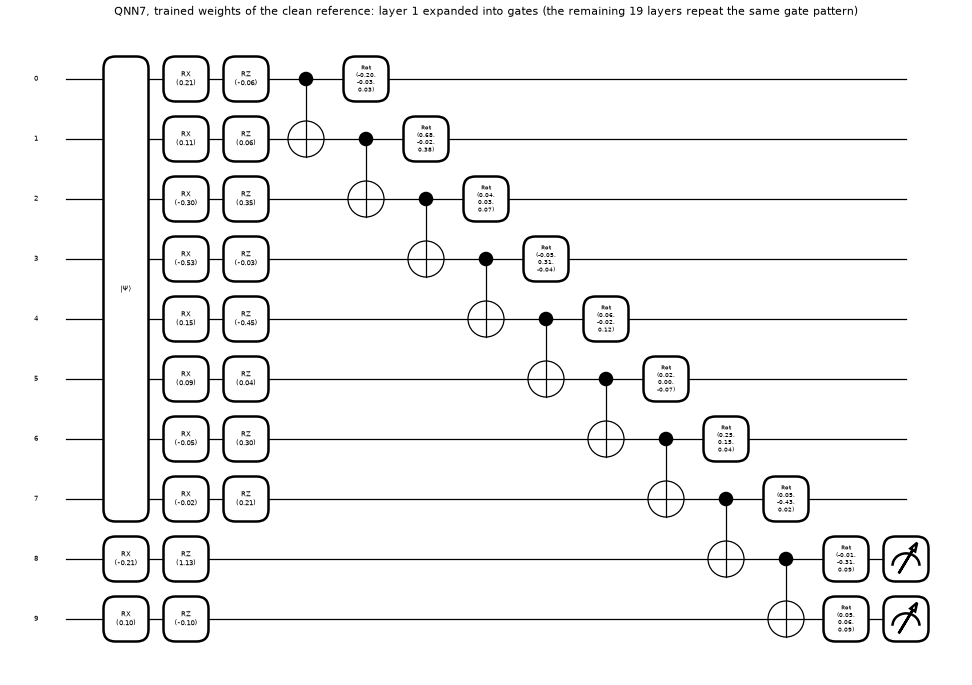

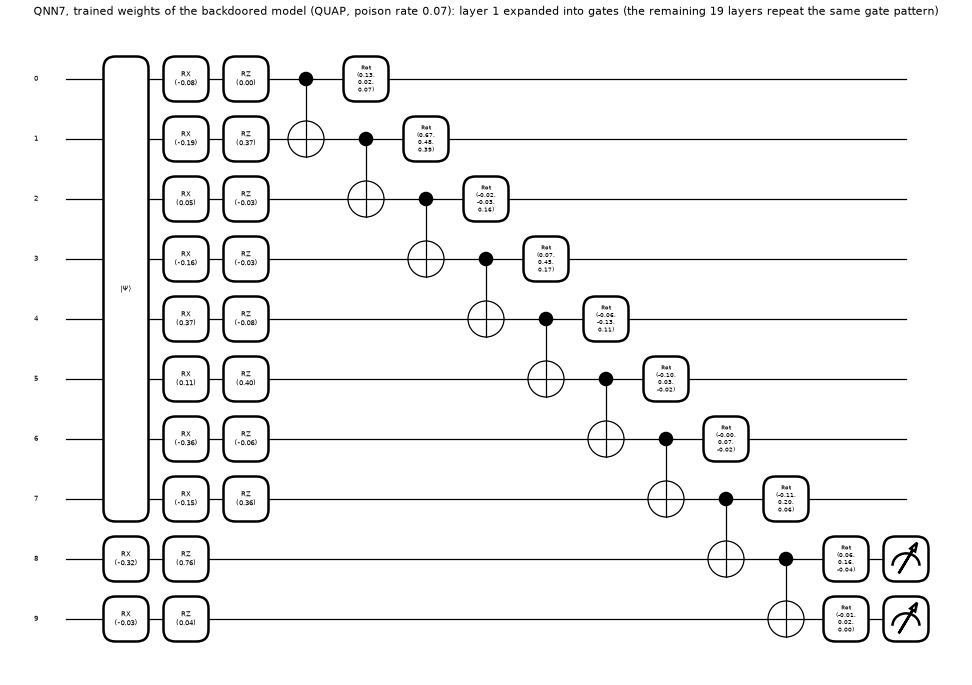

In [16]:
# One expanded layer with the TRAINED weights: clean reference versus the most heavily poisoned model of each architecture
for arch, (L, P) in ARCH.items():
    bd = [m for m in MODELS if m["arch"] == arch and m["rate"] > 0]
    if not bd: continue
    m = max(bd, key=lambda r: (r["rate"], -r["seed"])); ref = REFS[(arch, m["data"], m["seed"])]
    for tag, w in (("clean reference", ref["w"]), (f"backdoored model ({m['attack']}, poison rate {m['rate']:.2f})", m["w"])):
        w1 = w.numpy().astype(np.float64).reshape(L, N_Q, P // N_Q)[:1]
        draw(make_qnode(arch, L=1), (x0, w1), f"{arch}, trained weights of the {tag}: layer 1 expanded into gates (the remaining {L-1} layers repeat the same gate pattern)", level="device", fontsize=8, decimals=2)
    if arch not in DRAW_W: DRAW_W[arch] = (L, P)

## 6. The detector: Algorithm 1 from the paper

The detector needs only, for the model under test and the clean reference, the **class-probability vector for every input of the two pools**. The statistics are computed on those outputs:

* `shot_labels`: Eq. 12. For each input the probability vector `p` is turned into a finite-shot measurement: `n ~ Multinomial(S, p)` and the predicted class is `argmax n` (ties broken uniformly). This emulates a hardware interface that returns only frequencies.
* `mc_curves`: for each of M replications and each ratio rho, build the class-balanced mixed batch (Eq. 6: 250 inputs per class, of which `round(rho * 250)` come from *Du* and the rest from *Dc*), query both models **on the same batch**, form the prediction-rate vectors (Eq. 8), the gap (Eq. 9) and the DiD-aligned gap (Eq. 10).
* `sign_test_p` and `holm`: one-sided sign test over the M replications (Eq. 13), then Holm-Bonferroni over the K x (|R|-1) = 20 hypotheses (Eq. 14).
* `decide`: Eqs. 15-17 at rho_max: candidate class, effect size `gap*`, adjusted p-value `p*`, cold-zone value `cold*`, and the verdict.

**Why the DiD step matters.** Two clean models trained with different seeds already predict class frequencies slightly differently (`Delta_c(0) != 0`). Subtracting the gap at rho = 0 removes this static offset, so what remains grows with the dose of suspect inputs.
**Why the effect-size gate matters.** With 30 replications of 1000 inputs even tiny, harmless differences become statistically significant, so `p* < alpha` alone would raise many false alarms.

In [17]:
def shot_labels(rng, P, S):
    """Eq. 12: draw n ~ Multinomial(S, p) for every row of P and return argmax(n), ties broken uniformly at random."""
    n_left = np.full(len(P), S); rem = np.ones(len(P)); cnt = np.zeros(P.shape, dtype=np.int64)
    for c in range(P.shape[1] - 1):
        pc = np.clip(P[:, c] / np.maximum(rem, 1e-12), 0.0, 1.0)
        k = rng.binomial(n_left, pc); cnt[:, c] = k; n_left = n_left - k; rem = rem - P[:, c]
    cnt[:, -1] = n_left
    return (cnt + rng.random(cnt.shape) * 0.5).argmax(1)         # integer counts + noise < 1 breaks ties uniformly

def pred_rate(labels): return np.bincount(labels, minlength=K) / len(labels)          # Eq. 8

def mc_curves(rng, Pc_t, Pc_r, Pu_t, Pu_r, yc, yu, rhos=RHOS, N=BATCH_N, M=MC_RUNS, S=SHOTS, mode="equal"):
    """Monte Carlo replications. Pc_*/Pu_*: class-probability vectors of the model under test (_t) and of the reference (_r) on the pools Dc / Du.
    Returns D (M, |R|, K) = DiD-aligned gaps Delta_adj and G (M, |R|, K) = first-order gaps Delta."""
    ic = [np.flatnonzero(yc == c) for c in range(K)]; iu = [np.flatnonzero(yu == c) for c in range(K)]
    nper = N // K; D = np.zeros((M, len(rhos), K)); G = np.zeros_like(D)
    for m in range(M):
        gaps = np.zeros((len(rhos), K))
        for r, rho in enumerate(rhos):
            if mode == "equal":                                        # class-balanced mixing: Du carries the true labels
                nu = int(round(rho * nper)); nc = nper - nu
                sel_c = np.concatenate([rng.choice(ic[c], nc, replace=nc > len(ic[c])) for c in range(K)]) if nc else np.zeros(0, int)
                sel_u = np.concatenate([rng.choice(iu[c], nu, replace=nu > len(iu[c])) for c in range(K)]) if nu else np.zeros(0, int)
            else:                                                      # unstratified mixing
                nu = int(round(rho * N)); nc = N - nu
                sel_c = rng.choice(len(yc), nc, replace=nc > len(yc)); sel_u = rng.choice(len(yu), nu, replace=nu > len(yu))
            Pt = np.concatenate([Pc_t[sel_c], Pu_t[sel_u]]); Pr = np.concatenate([Pc_r[sel_c], Pu_r[sel_u]])      # the same mixed batch for both models
            gaps[r] = pred_rate(shot_labels(rng, Pt, S)) - pred_rate(shot_labels(rng, Pr, S))                    # Eq. 9
        G[m] = gaps; D[m] = gaps - gaps[0]                                                                       # Eq. 10
    return D, G

def sign_test_p(D):
    """One-sided sign test per (rho, c): P(Bin(M, 1/2) >= number of positive replications). Ties count as non-positive, so p_min = 2^-M. D: (M, |R'|, K)."""
    M = D.shape[0]; k = (D > 0).sum(0)
    return binom.sf(k - 1, M, 0.5)

def holm(p):
    """Holm-Bonferroni adjusted p-values (step-down, monotone) for an array of raw p-values of any shape."""
    flat = p.ravel(); H = len(flat); order = np.argsort(flat); adj = np.empty(H); run = 0.0
    for j, i in enumerate(order):
        run = max(run, min(1.0, (H - j) * flat[i])); adj[i] = run
    return adj.reshape(p.shape)

def decide(D, rhos=RHOS, tau=TAU, alpha=ALPHA, tau_cold=TAU_COLD, correction="holm", use_cold=True, test="sign"):
    """Eqs. 15-17 at rho_max. correction in {'holm', 'none'}; test in {'sign', 'wilcoxon'}."""
    mean = D.mean(0); nz = [i for i, r in enumerate(rhos) if r > 0]
    if test == "sign":
        raw = sign_test_p(D[:, nz, :])
    else:
        raw = np.ones((len(nz), D.shape[2]))
        for a, i in enumerate(nz):
            for c in range(D.shape[2]):
                x = D[:, i, c]
                raw[a, c] = 1.0 if np.allclose(x, 0) else wilcoxon(x, alternative="greater", zero_method="zsplit").pvalue
    padj = holm(raw) if correction == "holm" else raw
    top = len(rhos) - 1
    c_star = int(mean[top].argmax()); gap = float(mean[top, c_star]); p_star = float(padj[len(nz) - 1, c_star]); cold = float(np.delete(mean[top], c_star).min())
    det = (gap > tau) and (p_star < alpha) and ((cold < tau_cold) if use_cold else True)
    stars = np.zeros(mean.shape, dtype=bool)                  # cells (rho, c) that satisfy the rule if rho were the anchor (for the heat-maps)
    for a, i in enumerate(nz):
        c = int(mean[i].argmax())
        stars[i, c] = (mean[i, c] > tau) and (padj[a, c] < alpha) and (np.delete(mean[i], c).min() < tau_cold)
    return dict(detected=bool(det), c_star=c_star, gap=gap, p=p_star, cold=cold, mean=mean, padj=padj, stars=stars)

# ---- deterministic self-checks of the statistics ----
H_ = K * (len(RHOS) - 1)
print("hypothesis family |H| = K (|R| - 1) =", H_)
print("smallest attainable Holm-adjusted p for M = 30:", f"{H_ * 2.0**-30:.3e}", "(paper: 1.86e-8)")
floor = {M_: H_ * 2.0**-M_ for M_ in (5, 7, 8, 9, 10)}
print("Holm floor |H| 2^-M:", {k: round(v, 4) for k, v in floor.items()}, "-> significance feasible only for M >=", int(np.ceil(np.log2(H_ / ALPHA))))
Dtest = np.ones((30, len(RHOS), K)); Dtest[:, 0, :] = 0
print("all-positive replications -> raw p:", sign_test_p(Dtest[:, 1:, :])[0, 0], "= 2^-30 =", 2.0**-30, "| after Holm:", holm(sign_test_p(Dtest[:, 1:, :])).min())

hypothesis family |H| = K (|R| - 1) = 20
smallest attainable Holm-adjusted p for M = 30: 1.863e-08 (paper: 1.86e-8)
Holm floor |H| 2^-M: {5: 0.625, 7: 0.1562, 8: 0.0781, 9: 0.0391, 10: 0.0195} -> significance feasible only for M >= 9
all-positive replications -> raw p: 9.313225746154785e-10 = 2^-30 = 9.313225746154785e-10 | after Holm: 1.862645149230957e-08


## 7. Run the detector on every trained instance

For each model under test the notebook computes the class probabilities of the model and of its matched clean reference on the pools *Dc* (clean) and *Du* (every image carries the attack's trigger, pi = 1, true labels kept for class-balanced mixing), and runs Algorithm 1.
Note that the detector never sees the trigger, the target class, the weights or the poison rate: only the two probability vectors per input.

In [18]:
POOL_CACHE = {}
def pool_probs(arch, w, data, attack, seed, key):
    """Class probabilities of model w on the clean pool Dc and on the triggered suspect pool Du (cached)."""
    ck = (key, arch, data, attack, seed)
    if ck not in POOL_CACHE:
        (_, _), (Xte, yte) = SETS[data]; P = POOLS[data]; fn = TRIG[(attack, arch, seed)]["fn"]
        POOL_CACHE[ck] = (predict(arch, w, Xte[P["dc"]]), predict(arch, w, fn(Xte[P["du"]])))
    return POOL_CACHE[ck]

RES_ROWS, ARR = [], {}
t0 = time.time()
for mi, m in enumerate(MODELS):
    data, attack, arch, seed = m["data"], m["attack"], m["arch"], m["seed"]
    yc = SETS[data][1][1][POOLS[data]["dc"]]; yu = SETS[data][1][1][POOLS[data]["du"]]
    Pc_t, Pu_t = pool_probs(arch, m["w"], data, attack, seed, ("test", mi))
    ref = REFS[(arch, data, seed)]; Pc_r, Pu_r = pool_probs(arch, ref["w"], data, attack, seed, ("ref", arch, seed, attack))
    D, G = mc_curves(np.random.default_rng([SEED, mi]), Pc_t, Pc_r, Pu_t, Pu_r, yc, yu)
    out = decide(D)
    ARR[mi] = dict(D=D, G=G, mean=out["mean"], stars=out["stars"], Pc_t=Pc_t, Pc_r=Pc_r, Pu_t=Pu_t, Pu_r=Pu_r)
    RES_ROWS.append(dict(attack=attack, arch=arch, seed=seed, rate=m["rate"], backdoored=m["rate"] > 0, target=m["target"],
                         CDA=100 * m["cda"], ASR=100 * m["asr"], gap=out["gap"], c_hat=out["c_star"], p=out["p"], cold=out["cold"], detected=out["detected"]))
RES = pd.DataFrame(RES_ROWS)
RES["verdict"] = np.where(RES.detected, "Detected", "Pass")
print(f"detector run on {len(RES)} instances in {time.time()-t0:.0f} s")

detector run on 66 instances in 177 s


In [19]:
def show_table(attack, arch=None):
    d = RES[(RES.attack == attack) & ((RES.arch == arch) if arch else True)].copy()
    d["c_hat"] = "c" + d.c_hat.astype(str); d["FP/FN"] = np.where(d.detected & ~d.backdoored, "FP", np.where(~d.detected & d.backdoored, "FN", ""))
    d["localised"] = np.where(d.detected & d.backdoored, np.where(d.c_hat == "c" + d.target.astype(str), "yes", "NO"), "")
    d["p*"] = d.p.map(lambda v: f"{v:.2e}"); d["CDA(%)"] = d.CDA.round(1); d["ASR(%)"] = d.ASR.round(1)
    d["gap*"] = d.gap.round(4); d["cold*"] = d.cold.round(3)
    print(f"--- {attack} {arch or ''} (analogue of the paper's Tables " + {"QFGSM": "3", "QUAP": "4-6", "PATCH": "7"}[attack] + "; target class c" + str(int(d.target.iloc[0])) + ") ---")
    print(d[["arch", "seed", "rate", "CDA(%)", "ASR(%)", "gap*", "c_hat", "p*", "cold*", "verdict", "FP/FN", "localised"]].to_string(index=False))
for attack in ("QFGSM", "QUAP", "PATCH"):
    if (RES.attack == attack).any(): show_table(attack); print()

--- QFGSM  (analogue of the paper's Tables 3; target class c2) ---
arch  seed  rate  CDA(%)  ASR(%)   gap* c_hat       p*  cold*  verdict FP/FN localised
QNN1    20   0.0    90.5    14.4 0.0818    c3 1.86e-08 -0.095     Pass                
QNN1    20   0.2    91.4    38.4 0.0601    c2 1.86e-08 -0.037     Pass    FN          
QNN1    20   0.4    88.2    58.4 0.1874    c2 1.86e-08 -0.131 Detected             yes
QNN1    20   0.6    83.8    64.7 0.1288    c2 1.86e-08 -0.083 Detected             yes
QNN1    20   0.8    75.0    93.5 0.2423    c2 1.86e-08 -0.179 Detected             yes
QNN1    20   1.0    62.0   100.0 0.1357    c2 1.86e-08 -0.195 Detected             yes
QNN1    21   0.0    91.7    21.0 0.0723    c2 1.86e-08 -0.072     Pass                
QNN1    21   0.2    91.3    29.9 0.1120    c2 1.86e-08 -0.105 Detected             yes
QNN1    21   0.4    84.2    71.9 0.3191    c2 1.86e-08 -0.126 Detected             yes
QNN1    21   0.6    83.4    92.9 0.4408    c2 1.86e-08 -0.204 D

### Dose-response heat-maps (analogue of Figures 2-5)

Each panel shows, for one class, the Monte Carlo mean of the aligned gap `Delta_adj_c(rho)` (columns = mixing ratio rho, rows = poison rate of the model under test, first seed). Warm = the model under test predicts that class **more** often than the clean reference once suspect inputs are mixed in.
For a backdoored model the target class should get warmer to the right and downwards, and the other classes cooler (probability mass is conserved). A star marks a cell that satisfies the full rule if that rho were the anchor.

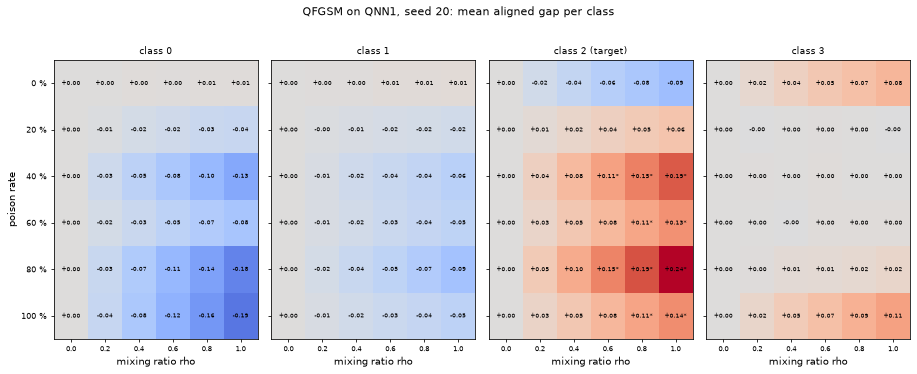

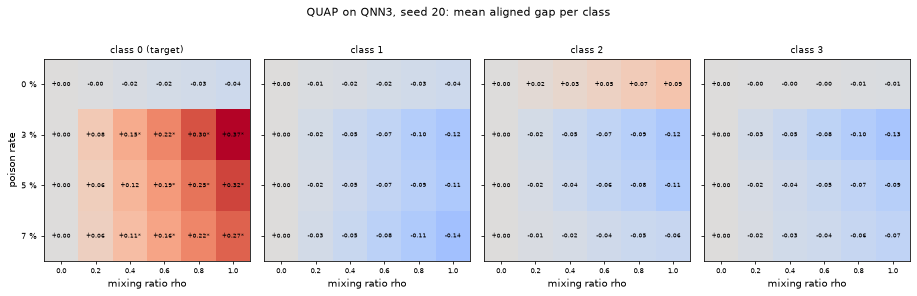

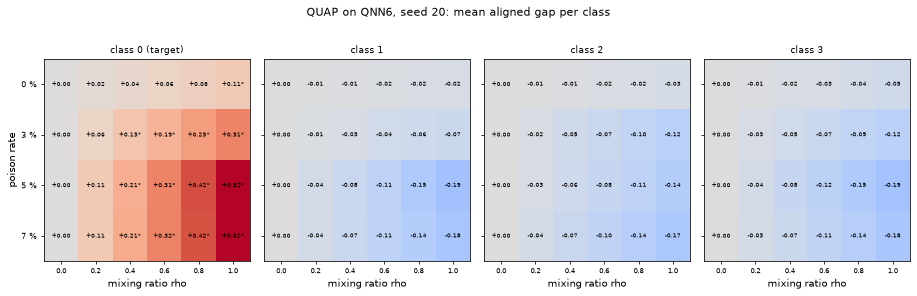

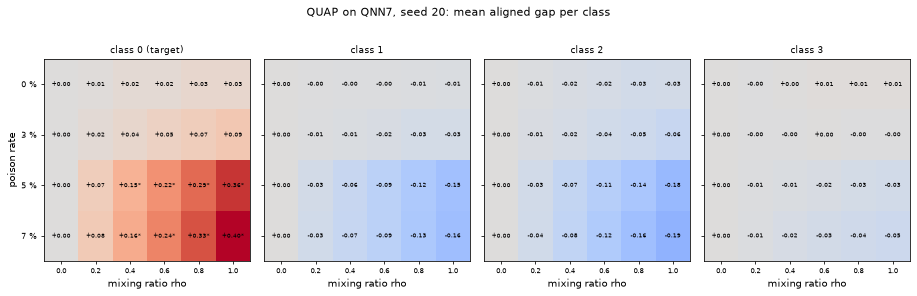

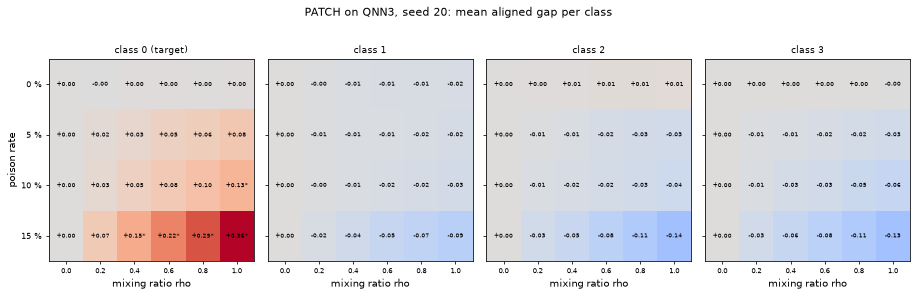

In [20]:
def heatmaps(attack, arch, seed):
    idx = [i for i in RES.index if RES.attack[i] == attack and RES.arch[i] == arch and RES.seed[i] == seed]
    idx = sorted(idx, key=lambda i: RES.rate[i]); tgt = int(RES.target[idx[0]])
    fig, axs = plt.subplots(1, K, figsize=(3.3 * K, 0.55 * len(idx) + 1.9), sharey=True)
    vm = max(0.15, max(np.abs(ARR[i]["mean"]).max() for i in idx))
    for c in range(K):
        Mc = np.stack([ARR[i]["mean"][:, c] for i in idx]); im = axs[c].imshow(Mc, cmap="coolwarm", vmin=-vm, vmax=vm, aspect="auto")
        for a, i in enumerate(idx):
            for r in range(len(RHOS)):
                axs[c].text(r, a, f"{ARR[i]['mean'][r, c]:+.2f}" + ("*" if ARR[i]["stars"][r, c] else ""), ha="center", va="center", fontsize=6)
        axs[c].set_xticks(range(len(RHOS))); axs[c].set_xticklabels([f"{r:.1f}" for r in RHOS], fontsize=7); axs[c].set_xlabel("mixing ratio rho"); axs[c].grid(False)
        axs[c].set_title(f"class {c}" + (" (target)" if c == tgt else ""), fontsize=9)
    axs[0].set_yticks(range(len(idx))); axs[0].set_yticklabels([f"{RES.rate[i]*100:.0f} %" for i in idx], fontsize=8); axs[0].set_ylabel("poison rate")
    fig.suptitle(f"{attack} on {arch}, seed {seed}: mean aligned gap per class", y=1.02, fontsize=11)
    plt.tight_layout(); plt.show()
for sp in GRID:
    heatmaps(sp["attack"], sp["arch"], SEEDS[0])

## 8. Overall detection performance (analogue of Table 8 and Figures 6-8)

Each trained instance is one evaluation sample. Sensitivity = detected backdoored models / backdoored models; specificity = passed clean controls / clean controls; precision and F1 as usual; localisation = share of true detections whose estimated target class is the real one.
The threshold-free view uses `gap*` as a continuous score: ROC curve and AUC, precision-recall curve and average precision (AP).

ALL instances: n = 66 (51 backdoored, 15 clean)   [paper: n = 110 (85 / 25)]
  sensitivity 0.863 (44/51)   specificity 0.667 (10/15)   precision 0.898   F1 0.880   localisation 1.000 (44/44)
  AUC(gap*) 0.880   AP(gap*) 0.963   [paper: sens 0.906, spec 0.840, prec 0.951, F1 0.928, localisation 0.987, AUC 0.954, AP 0.986]

attack arch  n_pos  n_neg  sens  spec   loc   AUC
 PATCH QNN3      9      3 0.667 1.000   6/6 0.889
 QFGSM QNN1     15      3 0.867 1.000 13/13 0.911
  QUAP QNN3      9      3 0.889 0.667   8/8 0.778
  QUAP QNN6      9      3 1.000 0.000   9/9 1.000
  QUAP QNN7      9      3 0.889 0.667   8/8 0.963


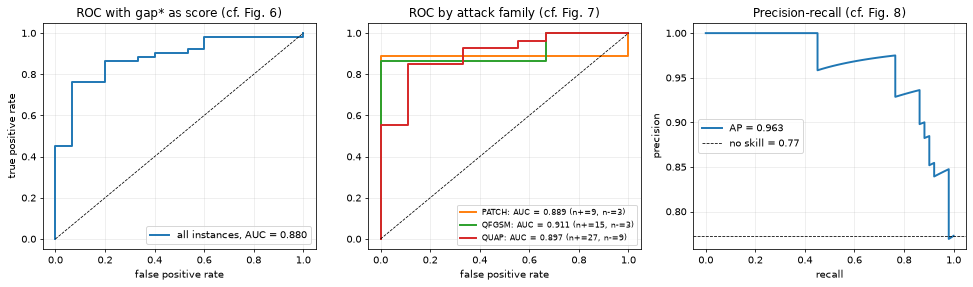

In [21]:
def metrics(det, truth, c_hat=None, target=None):
    det, truth = np.asarray(det, bool), np.asarray(truth, bool)
    tp, fp, fn, tn = int((det & truth).sum()), int((det & ~truth).sum()), int((~det & truth).sum()), int((~det & ~truth).sum())
    sens = tp / (tp + fn) if tp + fn else np.nan; spec = tn / (tn + fp) if tn + fp else np.nan
    prec = tp / (tp + fp) if tp + fp else np.nan; f1 = 2 * prec * sens / (prec + sens) if tp else (0.0 if tp + fp + fn else np.nan)
    loc = np.nan; nloc = ""
    if c_hat is not None:
        tpm = det & truth; loc = float((np.asarray(c_hat)[tpm] == np.asarray(target)[tpm]).mean()) if tpm.any() else np.nan
        nloc = f"{int((np.asarray(c_hat)[tpm] == np.asarray(target)[tpm]).sum())}/{int(tpm.sum())}"
    return dict(n=len(det), n_pos=int(truth.sum()), n_neg=int((~truth).sum()), TP=tp, FP=fp, FN=fn, TN=tn, sens=sens, spec=spec, prec=prec, F1=f1, loc=loc, loc_n=nloc)

def auc_ap(score, truth):
    truth = np.asarray(truth, bool)
    if truth.all() or (~truth).all(): return np.nan, np.nan
    return roc_auc_score(truth, score), average_precision_score(truth, score)

OV = metrics(RES.detected, RES.backdoored, RES.c_hat, RES.target); AUC_ALL, AP_ALL = auc_ap(RES.gap, RES.backdoored)
print(f"ALL instances: n = {OV['n']} ({OV['n_pos']} backdoored, {OV['n_neg']} clean)   [paper: n = 110 (85 / 25)]")
print(f"  sensitivity {OV['sens']:.3f} ({OV['TP']}/{OV['n_pos']})   specificity {OV['spec']:.3f} ({OV['TN']}/{OV['n_neg']})   precision {OV['prec']:.3f}   F1 {OV['F1']:.3f}   localisation {OV['loc']:.3f} ({OV['loc_n']})")
print(f"  AUC(gap*) {AUC_ALL:.3f}   AP(gap*) {AP_ALL:.3f}   [paper: sens 0.906, spec 0.840, prec 0.951, F1 0.928, localisation 0.987, AUC 0.954, AP 0.986]")
fam_rows = []
for key, d in RES.groupby(["attack", "arch"]):
    mm = metrics(d.detected, d.backdoored, d.c_hat, d.target); a, ap = auc_ap(d.gap, d.backdoored)
    fam_rows.append(dict(attack=key[0], arch=key[1], n_pos=mm["n_pos"], n_neg=mm["n_neg"], sens=mm["sens"], spec=mm["spec"], loc=mm["loc_n"], AUC=a))
print(); print(pd.DataFrame(fam_rows).round(3).to_string(index=False))

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
fpr, tpr, _ = roc_curve(RES.backdoored, RES.gap) if RES.backdoored.nunique() > 1 else ([0, 1], [0, 1], None)
axs[0].plot(fpr, tpr, lw=2, label=f"all instances, AUC = {AUC_ALL:.3f}"); axs[0].plot([0, 1], [0, 1], "k--", lw=0.8); axs[0].set_xlabel("false positive rate"); axs[0].set_ylabel("true positive rate"); axs[0].set_title("ROC with gap* as score (cf. Fig. 6)"); axs[0].legend()
for fam, col in (("PATCH", "C1"), ("QFGSM", "C2"), ("QUAP", "C3")):
    d = RES[RES.attack == fam]
    if d.backdoored.nunique() > 1:
        f_, t_, _ = roc_curve(d.backdoored, d.gap); axs[1].plot(f_, t_, color=col, lw=2, label=f"{fam}: AUC = {roc_auc_score(d.backdoored, d.gap):.3f} (n+={int(d.backdoored.sum())}, n-={int((~d.backdoored).sum())})")
axs[1].plot([0, 1], [0, 1], "k--", lw=0.8); axs[1].set_xlabel("false positive rate"); axs[1].set_title("ROC by attack family (cf. Fig. 7)"); axs[1].legend(fontsize=8)
if RES.backdoored.nunique() > 1:
    pr, rc, _ = precision_recall_curve(RES.backdoored, RES.gap); axs[2].plot(rc, pr, lw=2, label=f"AP = {AP_ALL:.3f}")
axs[2].axhline(RES.backdoored.mean(), color="k", ls="--", lw=0.8, label=f"no skill = {RES.backdoored.mean():.2f}"); axs[2].set_xlabel("recall"); axs[2].set_ylabel("precision"); axs[2].set_title("Precision-recall (cf. Fig. 8)"); axs[2].legend()
plt.tight_layout(); plt.show()

## 9. Ablations and sensitivity (analogue of Tables 9-12)

All variants reuse the **stored Monte Carlo arrays**, so they differ from the full pipeline in exactly one component:

* *Full* = three gates (effect size, Holm-adjusted significance, cold zone). *Two-condition baseline* = without the cold-zone gate. Every other row modifies one component of that baseline.
* *- DiD*: test the first-order gaps `Delta_c(rho)` instead of the aligned gaps. *M = 5*: only the first 5 replications. *- Holm*: raw sign-test p-values. *Wilcoxon*: signed-rank test instead of the sign test.
* The paper's "- MC (M = 1, z-test)" row is not reproduced (a single-batch z-test needs its own variance model).

Then the sweep of the Monte Carlo budget M (Table 10) and of the effect-size threshold tau (Table 12).

In [22]:
def variant(name, D_key="D", M=None, **kw):
    rows = []
    for i in RES.index:
        D = ARR[i][D_key] if M is None else ARR[i][D_key][:M]
        o = decide(D, **kw); rows.append((o["detected"], o["gap"], o["p"], o["c_star"]))
    det, gap, p, c = (np.array(x) for x in zip(*rows)); truth = RES.backdoored.values
    mm = metrics(det, truth); a, _ = auc_ap(gap, truth); tp = det & truth
    return dict(variant=name, FP=mm["FP"], FN=mm["FN"], sens=mm["sens"], spec=mm["spec"], prec=mm["prec"], F1=mm["F1"], AUC_gap=a,
                gap_pos=float(gap[tp].mean()) if tp.any() else np.nan, neg_log10_p_pos=float((-np.log10(np.maximum(p[tp], 1e-300))).mean()) if tp.any() else np.nan)
ABL = pd.DataFrame([
    variant("Full (three gates)"),
    variant("Two-condition baseline (no cold zone)", use_cold=False),
    variant("  - DiD (test first-order gaps)", D_key="G", use_cold=False),
    variant("  M = 5 replications", M=5, use_cold=False),
    variant("  - Holm correction", correction="none", use_cold=False),
    variant("  Wilcoxon instead of sign test", test="wilcoxon", use_cold=False)])
print(ABL.round(3).to_string(index=False))
print("\npaper Table 9: Full FP 4 FN 8 sens .906 spec .840 | two-cond FP 5 FN 8 spec .800 | -DiD FP 4 FN 8 | M=5: sens 0 (FN = all) | -Holm FP 5 FN 8 | Wilcoxon FP 5 FN 8")

print("\nMonte Carlo budget M (statistical gate only, cold zone omitted; paper Table 10: no detection for M <= 7, sensitivity .906 from M = 9)")
sw = []
for M_ in (5, 7, 9, 10, 15, 20, 30):
    v = variant(f"M = {M_}", M=M_, use_cold=False); sw.append(dict(M=M_, p_min_raw=2.0**-M_, p_min_Holm=H_ * 2.0**-M_, feasible=H_ * 2.0**-M_ < ALPHA, sens=v["sens"], spec=v["spec"], F1=v["F1"]))
print(pd.DataFrame(sw).round(4).to_string(index=False))

print("\nEffect-size threshold tau (alpha = 0.05, cold zone omitted; paper Table 12: sens .988/.906/.812/.741, spec .56/.80/.92/.96)")
tw = []
for tau_ in (0.05, 0.10, 0.15, 0.20):
    v = variant(f"tau = {tau_}", tau=tau_, use_cold=False); tw.append(dict(tau=tau_, sens=v["sens"], spec=v["spec"], Youden_J=v["sens"] + v["spec"] - 1))
TAUSW = pd.DataFrame(tw); print(TAUSW.round(3).to_string(index=False))

print("\nValue of the effect-size gate (paper Table 11): p-value gate only vs joint gate, per family")
t11 = []
for key, d in RES.groupby(["attack", "arch"]):
    ix = d.index
    for lab, kw in (("p-value gate", dict(tau=-1.0)), ("joint gate", dict())):
        det = np.array([decide(ARR[i]["D"], use_cold=False, **kw)["detected"] for i in ix]); mm = metrics(det, d.backdoored.values)
        t11.append(dict(attack=key[0], arch=key[1], gate=lab, sens=mm["sens"], spec=mm["spec"]))
print(pd.DataFrame(t11).round(2).to_string(index=False))

                              variant  FP  FN  sens  spec  prec    F1  AUC_gap  gap_pos  neg_log10_p_pos
                   Full (three gates)   5   7 0.863 0.667 0.898 0.880    0.880    0.310            7.730
Two-condition baseline (no cold zone)   5   7 0.863 0.667 0.898 0.880    0.880    0.310            7.730
        - DiD (test first-order gaps)   7   5 0.902 0.533 0.868 0.885    0.873    0.371            7.730
                   M = 5 replications   0  51 0.000 1.000   NaN 0.000    0.882      NaN              NaN
                    - Holm correction   5   7 0.863 0.667 0.898 0.880    0.880    0.310            9.031
        Wilcoxon instead of sign test   5   7 0.863 0.667 0.898 0.880    0.880    0.310            4.766

paper Table 9: Full FP 4 FN 8 sens .906 spec .840 | two-cond FP 5 FN 8 spec .800 | -DiD FP 4 FN 8 | M=5: sens 0 (FN = all) | -Holm FP 5 FN 8 | Wilcoxon FP 5 FN 8

Monte Carlo budget M (statistical gate only, cold zone omitted; paper Table 10: no detection for M <=

 M  p_min_raw  p_min_Holm  feasible   sens   spec   F1
 5     0.0312      0.6250     False 0.0000 1.0000 0.00
 7     0.0078      0.1562     False 0.0000 1.0000 0.00
 9     0.0020      0.0391      True 0.8627 0.6667 0.88
10     0.0010      0.0195      True 0.8627 0.6667 0.88
15     0.0000      0.0006      True 0.8627 0.6667 0.88
20     0.0000      0.0000      True 0.8627 0.6667 0.88
30     0.0000      0.0000      True 0.8627 0.6667 0.88

Effect-size threshold tau (alpha = 0.05, cold zone omitted; paper Table 12: sens .988/.906/.812/.741, spec .56/.80/.92/.96)


 tau  sens  spec  Youden_J
0.05 0.980 0.400     0.380
0.10 0.863 0.667     0.529
0.15 0.745 0.933     0.678
0.20 0.686 0.933     0.620

Value of the effect-size gate (paper Table 11): p-value gate only vs joint gate, per family
attack arch         gate  sens  spec
 PATCH QNN3 p-value gate  1.00  0.00
 PATCH QNN3   joint gate  0.67  1.00
 QFGSM QNN1 p-value gate  1.00  0.00
 QFGSM QNN1   joint gate  0.87  1.00
  QUAP QNN3 p-value gate  1.00  0.00
  QUAP QNN3   joint gate  0.89  0.67
  QUAP QNN6 p-value gate  1.00  0.00
  QUAP QNN6   joint gate  1.00  0.00
  QUAP QNN7 p-value gate  1.00  0.00
  QUAP QNN7   joint gate  0.89  0.67


## 10. Detection power under partial contamination, cross-architecture references, and a classical control

**Contamination (Section 5.11, Figure 9, Table 13).** In practice only a fraction pi of the suspect pool carries the trigger. Starting from *clean* *Du* images, a random pi-fraction receives the trigger, and the detector (full rule) is run several times per backdoored model and per clean control. The expected triggered share of a batch is rho pi, so small pi means a weak dose.
`pi_0.9` is the smallest pi with detection rate >= 0.9 (linear interpolation).

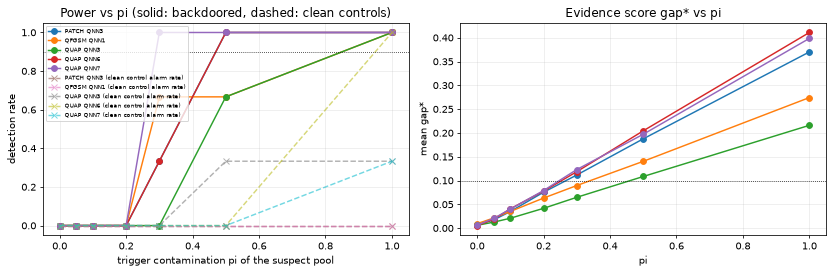

pi_0.9 (tau = 0.10): {'PATCH QNN3': 0.47, 'QFGSM QNN1': 0.85, 'QUAP QNN3': 0.85, 'QUAP QNN6': 0.47, 'QUAP QNN7': 0.29}   [paper Table 13, top poison rates: PATCH QNN3 p15 0.275, QUAP QNN3 p7 0.450, QUAP QNN6 p7 0.475, QUAP QNN7 p7 0.750]
detection rate of backdoored models at pi = 0: 0.00  [paper: zero detections]   (331 s)


In [23]:
def run_detector_probs(rng, Pc_t, Pc_r, Pu_t, Pu_r, yc, yu, **kw):
    D, G = mc_curves(rng, Pc_t, Pc_r, Pu_t, Pu_r, yc, yu); return decide(D, **kw)

def pi_sweep(sel_idx, tag, n_rep, tau=TAU):
    rows = []
    for mi in sel_idx:
        m = MODELS[mi]; data, attack, arch, seed = m["data"], m["attack"], m["arch"], m["seed"]
        (_, _), (Xte, yte) = SETS[data]; P = POOLS[data]; yc, yu = yte[P["dc"]], yte[P["du"]]
        ref = REFS[(arch, data, seed)]; A = ARR[mi]
        Xu_clean = Xte[P["du"]]; Pu_clean_t, Pu_clean_r = predict(arch, m["w"], Xu_clean), predict(arch, ref["w"], Xu_clean)
        for pi_ in PI_LIST:
            for rep in range(n_rep):
                r = np.random.default_rng([SEED, mi, int(1000 * pi_), rep])
                mask = np.zeros(len(yu), bool); mask[r.choice(len(yu), int(round(pi_ * len(yu))), replace=False)] = True
                Pu_t = np.where(mask[:, None], A["Pu_t"], Pu_clean_t); Pu_r = np.where(mask[:, None], A["Pu_r"], Pu_clean_r)
                o = run_detector_probs(r, A["Pc_t"], A["Pc_r"], Pu_t, Pu_r, yc, yu, tau=tau)
                rows.append(dict(attack=attack, arch=arch, seed=seed, rate=m["rate"], pi=pi_, detected=o["detected"], gap=o["gap"], tag=tag))
    return pd.DataFrame(rows)

t0 = time.time(); n_rep = 2
top_rate = {(sp["attack"], sp["arch"]): max(sp["rates"]) for sp in GRID}
bd_idx = [i for i, m in enumerate(MODELS) if m["rate"] == top_rate[(m["attack"], m["arch"])] and m["rate"] > 0]
cl_idx = [i for i, m in enumerate(MODELS) if m["rate"] == 0]
PIS = pd.concat([pi_sweep(bd_idx, "backdoored", n_rep), pi_sweep(cl_idx, "clean control", n_rep)])
PIS["config"] = PIS.attack + " " + PIS.arch
curve = PIS.groupby(["tag", "config", "pi"]).agg(rate=("detected", "mean"), gap=("gap", "mean")).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for cfg, g in curve[curve.tag == "backdoored"].groupby("config"):
    axs[0].plot(g.pi, g.rate, marker="o", label=cfg); axs[1].plot(g.pi, g.gap, marker="o", label=cfg)
for cfg, g in curve[curve.tag == "clean control"].groupby("config"):
    axs[0].plot(g.pi, g.rate, ls="--", marker="x", alpha=0.6, label=cfg + " (clean control alarm rate)")
axs[0].axhline(0.9, color="k", lw=0.8, ls=":"); axs[0].set_xlabel("trigger contamination pi of the suspect pool"); axs[0].set_ylabel("detection rate"); axs[0].set_title("Power vs pi (solid: backdoored, dashed: clean controls)"); axs[0].legend(fontsize=6)
axs[1].axhline(TAU, color="k", lw=0.8, ls=":"); axs[1].set_xlabel("pi"); axs[1].set_ylabel("mean gap*"); axs[1].set_title("Evidence score gap* vs pi"); plt.tight_layout(); plt.show()
def pi09(g):
    g = g.sort_values("pi"); x, y = g.pi.values, g.rate.values
    if y.max() < 0.9: return np.nan
    j = int(np.argmax(y >= 0.9));
    return float(x[j]) if j == 0 else float(x[j-1] + (0.9 - y[j-1]) * (x[j] - x[j-1]) / (y[j] - y[j-1]))
print("pi_0.9 (tau = 0.10):", {cfg: (round(pi09(g), 3) if pi09(g) == pi09(g) else '>1.0') for cfg, g in curve[curve.tag == 'backdoored'].groupby('config')}, "  [paper Table 13, top poison rates: PATCH QNN3 p15 0.275, QUAP QNN3 p7 0.450, QUAP QNN6 p7 0.475, QUAP QNN7 p7 0.750]")
PI0 = PIS[(PIS.tag == "backdoored") & (PIS.pi == 0.0)].detected.mean()
print(f"detection rate of backdoored models at pi = 0: {PI0:.2f}  [paper: zero detections]   ({time.time()-t0:.0f} s)")

**Cross-architecture reference (Section 5.12, Table 14).** The QUAP-tested model of one architecture is compared with a clean reference of a *different* architecture (same seed), without any retraining.
This needs the QUAP models of QNN3, QNN6 and QNN7, so it runs only when all three are in the grid (the full run).

In [24]:
quap_arch = sorted({m["arch"] for m in MODELS if m["attack"] == "QUAP"})
if len(quap_arch) < 3:
    print("Cross-architecture matrix skipped in this run (needs QUAP on QNN3, QNN6 and QNN7: set FAST_MODE = False).")
    XARCH = None
else:
    rows = []
    for mi, m in enumerate(MODELS):
        if m["attack"] != "QUAP": continue
        data, seed = m["data"], m["seed"]; (_, _), (Xte, yte) = SETS[data]; P = POOLS[data]; yc, yu = yte[P["dc"]], yte[P["du"]]
        fn = TRIG[("QUAP", m["arch"], seed)]["fn"]
        for ra in quap_arch:
            if ra == m["arch"]: continue
            rw = REFS[(ra, data, seed)]["w"]; Pc_r, Pu_r = predict(ra, rw, Xte[P["dc"]]), predict(ra, rw, fn(Xte[P["du"]]))
            o = run_detector_probs(np.random.default_rng([SEED, mi, 7, list(ARCH).index(ra)]), ARR[mi]["Pc_t"], Pc_r, ARR[mi]["Pu_t"], Pu_r, yc, yu)
            rows.append(dict(tested=m["arch"], reference=ra, seed=seed, rate=m["rate"], backdoored=m["rate"] > 0, detected=o["detected"], c_hat=o["c_star"], target=m["target"]))
    XR = pd.DataFrame(rows); out = []
    for (t_, r_), d in XR.groupby(["tested", "reference"]):
        mm = metrics(d.detected, d.backdoored, d.c_hat, d.target); out.append(dict(tested=t_, reference=r_, runs=len(d), sens=mm["sens"], spec=mm["spec"], localisation=mm["loc_n"], TP=mm["TP"], TN=mm["TN"], FP=mm["FP"], FN=mm["FN"]))
    mm = metrics(XR.detected, XR.backdoored, XR.c_hat, XR.target); out.append(dict(tested="aggregate", reference="mismatched", runs=len(XR), sens=mm["sens"], spec=mm["spec"], localisation=mm["loc_n"], TP=mm["TP"], TN=mm["TN"], FP=mm["FP"], FN=mm["FN"]))
    XARCH = pd.DataFrame(out); print(XARCH.round(3).to_string(index=False)); print("paper Table 14 aggregate: sensitivity 96.7 % (87/90), specificity 80.0 % (24/30)")

   tested  reference  runs  sens  spec localisation  TP  TN  FP  FN
     QNN3       QNN6    12 0.889 0.667          8/8   8   2   1   1
     QNN3       QNN7    12 0.889 0.667          8/8   8   2   1   1
     QNN6       QNN3    12 1.000 0.667          9/9   9   2   1   0
     QNN6       QNN7    12 1.000 0.667          9/9   9   2   1   0
     QNN7       QNN3    12 0.889 0.333          8/8   8   1   2   1
     QNN7       QNN6    12 1.000 0.333          9/9   9   1   2   0
aggregate mismatched    72 0.944 0.556        51/51  51  10   8   3
paper Table 14 aggregate: sensitivity 96.7 % (87/90), specificity 80.0 % (24/30)


**Classical control: the same detector on random forests.** A random forest (on the same amplitude-normalised pixels) is trained on PATCH-poisoned data at several rates, a clean control and a clean reference. The detector only needs `predict_proba`, so it can screen these classical models without any change.
This is a control for the *detector*, not a claim of the paper: it shows how much of the behaviour is due to the statistics and how much to the quantum model.

In [25]:
RF_ROWS = []
data = "B0123"; seed0 = SEEDS[0]; X, y = subset(data, seed0); tgt = TARGETS[data]; fnp = patch_trigger
(_, _), (Xte, yte) = SETS[data]; P = POOLS[data]; yc, yu = yte[P["dc"]], yte[P["du"]]; Xev, yev = Xte[P["ev"]], yte[P["ev"]]
def rf_fit(Xa, ya, s): return RandomForestClassifier(n_estimators=RF_TREES, random_state=s, n_jobs=1).fit(amp(Xa), ya)
rf_ref = rf_fit(X, y, 1)
Pc_r, Pu_r = rf_ref.predict_proba(amp(Xte[P["dc"]])), rf_ref.predict_proba(amp(fnp(Xte[P["du"]])))
for j, rate in enumerate((0.0, 0.05, 0.10, 0.15)):
    Xp, yp = poison_set(X, y, fnp, tgt, int(round(rate * len(X))), seed=7 + j); rf = rf_fit(Xp, yp, 10 + j)
    cda = (rf.predict(amp(Xev)) == yev).mean(); nt = yev != tgt; asr = (rf.predict(amp(fnp(Xev[nt]))) == tgt).mean()
    Pc_t, Pu_t = rf.predict_proba(amp(Xte[P["dc"]])), rf.predict_proba(amp(fnp(Xte[P["du"]])))
    o = run_detector_probs(np.random.default_rng([SEED, 99, j]), Pc_t, Pc_r, Pu_t, Pu_r, yc, yu)
    RF_ROWS.append(dict(model="random forest", attack="PATCH", poison_rate=rate, CDA=round(100 * cda, 1), ASR=round(100 * asr, 1), gap=round(o["gap"], 4), c_hat=o["c_star"], p=f"{o['p']:.2e}", verdict="Detected" if o["detected"] else "Pass"))
RFT = pd.DataFrame(RF_ROWS); print(RFT.to_string(index=False))

        model attack  poison_rate  CDA   ASR    gap  c_hat        p  verdict
random forest  PATCH         0.00 98.3   0.4 0.0030      2 8.68e-06     Pass
random forest  PATCH         0.05 98.3 100.0 0.7485      0 1.86e-08 Detected
random forest  PATCH         0.10 98.3 100.0 0.7466      0 1.86e-08 Detected
random forest  PATCH         0.15 98.1 100.0 0.7487      0 1.86e-08 Detected


## 11. Side by side with the paper

Verdict rule: "reproduced" when the notebook value is within 0.02 of the paper value (the tolerance for accuracy-like and F1 numbers; it is **tight compared with the sampling error** of 15-45 instances, treat it with that in mind);
"not reached" / "exceeded" with the gap otherwise; "cannot be checked" when the run does not contain the needed configuration. Qualitative and deterministic claims are tested directly.

In [26]:
rows = []
def cmp(claim, paper, nb, tol=0.02, fmt="{:.3f}"):
    if nb is None or (isinstance(nb, float) and np.isnan(nb)):
        rows.append(dict(claim=claim, paper=fmt.format(paper), notebook="n/a", verdict="cannot be checked in this run")); return
    d = nb - paper
    v = "reproduced" if abs(d) <= tol else (f"exceeded by {d:+.3f}" if d > 0 else f"not reached ({d:+.3f})")
    rows.append(dict(claim=claim, paper=fmt.format(paper), notebook=fmt.format(nb), verdict=v))
def qual(claim, paper, nb_text, ok):
    rows.append(dict(claim=claim, paper=paper, notebook=nb_text, verdict="cannot be checked in this run" if ok is None else ("reproduced" if ok else "not reached")))

cmp("1 overall sensitivity", 0.906, OV["sens"]); cmp("1 overall specificity", 0.840, OV["spec"]); cmp("1 overall precision", 0.951, OV["prec"]); cmp("1 overall F1", 0.928, OV["F1"])
cmp("2 AUC of gap*", 0.954, AUC_ALL); cmp("2 AP of gap*", 0.986, AP_ALL)
for fam, pa in (("PATCH", 1.0), ("QFGSM", 1.0), ("QUAP", 0.976)):
    d = RES[RES.attack == fam]; cmp(f"2 AUC {fam}", pa, auc_ap(d.gap, d.backdoored)[0] if len(d) else None)
cmp("3 target localisation among detections", 0.987, OV["loc"])
d = RES[RES.attack == "QFGSM"]
if len(d):
    cl = d[~d.backdoored]; bd = d[d.backdoored]; cmp("4 Q-FGSM clean-control specificity", 1.0, float((~cl.detected).mean()) if len(cl) else None)
    cmp("4 Q-FGSM sensitivity, poison > 0 (paper 20-100 %)", 0.72, float(bd.detected.mean()) if len(bd) else None)
d = RES[RES.attack == "PATCH"]
if len(d):
    cmp("4 PATCH sensitivity", 1.0, float(d[d.backdoored].detected.mean())); cmp("4 PATCH clean-control specificity", 1.0, float((~d[~d.backdoored].detected).mean()))
for arch, ps, pp in (("QNN3", 1.0, 0.6), ("QNN6", 1.0, 1.0), ("QNN7", 0.93, 0.6)):
    d = RES[(RES.attack == "QUAP") & (RES.arch == arch)]
    cmp(f"4 QUAP {arch} sensitivity (p3-p7)", ps, float(d[d.backdoored].detected.mean()) if len(d) else None)
    cmp(f"4 QUAP {arch} clean-control specificity", pp, float((~d[~d.backdoored].detected).mean()) if len(d) else None)

# claim 5: dose-response monotonicity of the target-class aligned gap
mono = []
for i in RES.index[RES.backdoored]:
    t = ARR[i]["mean"][:, int(RES.target[i])]; mono.append(bool(np.all(np.diff(t) > -0.02)))
tgt_gap = np.mean([ARR[i]["mean"][-1, int(RES.target[i])] for i in RES.index[RES.backdoored]]); non_gap = np.mean([np.delete(ARR[i]["mean"][-1], int(RES.target[i])).mean() for i in RES.index[RES.backdoored]])
qual("5 target-class aligned gap grows with rho (share of backdoored instances, tolerance 0.02)", "monotone dose-response", f"{np.mean(mono):.2f} monotone; mean target uplift {tgt_gap:+.3f}, mean other classes {non_gap:+.3f} at rho = 1", np.mean(mono) >= 0.9 and tgt_gap > 0 > non_gap)
qual("6 Holm floor 20 * 2^-M (M = 30: 1.86e-8; no detection for M <= 8)", "1.86e-8; sens 0 for M <= 8", f"{H_*2.0**-30:.2e}; M=5 sensitivity {ABL.loc[ABL.variant.str.contains('M = 5'), 'sens'].iloc[0]:.2f}", bool(np.isclose(H_ * 2.0**-30, 1.86e-8, rtol=0.01)) and ABL.loc[ABL.variant.str.contains('M = 5'), 'sens'].iloc[0] == 0.0)
b2, bf = ABL.iloc[1], ABL.iloc[0]
qual("7 removing the cold zone does not reduce false positives (FP full <= FP two-condition)", "FP 4 -> 5", f"FP {bf.FP} -> {b2.FP}", bool(bf.FP <= b2.FP))
qual("7 removing DiD / Holm / using Wilcoxon changes binary metrics little (|delta F1| <= 0.03 vs two-condition)", "identical binary counts", f"max |delta F1| = {np.nanmax(np.abs(ABL.F1.values[[2, 4, 5]] - b2.F1)):.3f}", bool(np.nanmax(np.abs(ABL.F1.values[[2, 4, 5]] - b2.F1)) <= 0.03))
qual("8 sensitivity falls and specificity rises with tau", "Table 12", f"sens {TAUSW.sens.round(2).tolist()}, spec {TAUSW.spec.round(2).tolist()}", bool((np.diff(TAUSW.sens) <= 1e-9).all() and (np.diff(TAUSW.spec) >= -1e-9).all()))
qual("9 no detections of backdoored models at pi = 0", "0 detections", f"detection rate {PI0:.2f}", PI0 == 0.0)
if XARCH is not None:
    ag = XARCH.iloc[-1]; cmp("10 cross-architecture sensitivity", 0.967, float(ag.sens)); cmp("10 cross-architecture specificity", 0.80, float(ag.spec))
else:
    rows.append(dict(claim="10 cross-architecture reference matrix", paper="sens 96.7 %, spec 80.0 %", notebook="n/a", verdict="cannot be checked in this run"))
cdas = np.array([m["cda"] for m in MODELS if m["rate"] == 0]); qual("11 clean-data accuracy 90-95 % of clean controls", "90.2-94.6 %", f"mean {100*cdas.mean():.1f} % (range {100*cdas.min():.1f}-{100*cdas.max():.1f}); training sets of {N_TRAIN} images, {EPOCHS} epochs", None if len(cdas) == 0 else bool(cdas.mean() >= 0.90))
rows.append(dict(claim="5.13 QSentry-style baseline (stronger access)", paper="3/15 detected, 5/5 clean passed", notebook="not implemented", verdict="cannot be checked in this run"))
COMPARE = pd.DataFrame(rows)
for _, r in COMPARE.iterrows():
    print(f"[{r.verdict}]  {r.claim}\n      paper: {r.paper}   |   this notebook: {r.notebook}")
print("\nverdict counts:", COMPARE.verdict.str.split(" ").str[0].value_counts().to_dict())
print(f"\ntotal notebook time so far: {(time.time()-T0_NOTEBOOK)/60:.1f} min (model training: {TRAIN_MINUTES:.1f} min); FAST_MODE = {FAST_MODE}")

[not reached (-0.043)]  1 overall sensitivity
      paper: 0.906   |   this notebook: 0.863
[not reached (-0.173)]  1 overall specificity
      paper: 0.840   |   this notebook: 0.667
[not reached (-0.053)]  1 overall precision
      paper: 0.951   |   this notebook: 0.898
[not reached (-0.048)]  1 overall F1
      paper: 0.928   |   this notebook: 0.880
[not reached (-0.074)]  2 AUC of gap*
      paper: 0.954   |   this notebook: 0.880
[not reached (-0.023)]  2 AP of gap*
      paper: 0.986   |   this notebook: 0.963
[not reached (-0.111)]  2 AUC PATCH
      paper: 1.000   |   this notebook: 0.889
[not reached (-0.089)]  2 AUC QFGSM
      paper: 1.000   |   this notebook: 0.911
[not reached (-0.079)]  2 AUC QUAP
      paper: 0.976   |   this notebook: 0.897
[reproduced]  3 target localisation among detections
      paper: 0.987   |   this notebook: 1.000
[reproduced]  4 Q-FGSM clean-control specificity
      paper: 1.000   |   this notebook: 1.000
[exceeded by +0.147]  4 Q-FGSM sensit

## 12. Reading the paper critically

* **What is solid.** The statistics are sound and cheap: a paired, same-batch comparison with a clean reference, a sign test that needs no distributional assumption, Holm correction, and an explicit effect-size gate. The deterministic parts (the Holm floor `20 * 2^-M`, zero power at pi = 0) are exactly reproducible. The dose-response picture (target class warms with rho, other classes cool) is easy to see in the heat-maps above.
* **What depends on the benchmark design.** *Du* is synthetically triggered with pi = 1 and the *same* trigger that was used for poisoning, i.e. the best case for the defender. Real suspect pools will contain few or no triggered inputs; the contamination sweep shows how quickly power drops. The detector also needs a matched clean reference and a trusted clean pool of the same distribution; the clean-control false alarms (QUAP) show that a benign shift between *Dc* and *Du* (here: a universal perturbation that fools even clean models) is read as evidence.
* **Specificity is the weak spot.** The effect-size threshold tau = 0.10 was chosen on the same 110 instances that are then reported (the paper says thresholds should be calibrated on benign controls and fixed before testing); with 5-25 clean controls the specificity estimates have very wide error bars.
* **Under-specified setup.** Training budgets, learning rates, poison-rate semantics, trigger magnitudes, the patch pattern and the QNN6 rotation layout are not given, and the data are not public. Different (reasonable) choices move CDA, ASR and especially the false-target rate of the trigger on clean models, and that last number drives the false-alarm rate.
* **Threat model.** A backdoor that is only active for inputs far from the suspect pool, or a target class that the clean reference also over-predicts on *Du*, would be missed or confused. "Pass" is evidence of absence only for the queried *Du(pi)*, as the paper itself says.
* **Scale.** The paper's trained instances (full MNIST subsets, 5 seeds, 110 instances) were replaced here by small training subsets and fewer seeds, so absolute CDA is lower and the aggregate metrics are noisier than the paper's.

## 13. Exercises

1. **Dose-response by hand.** Pick one backdoored instance and plot `Delta_c(rho)` (array `G`) and `Delta_adj_c(rho)` (array `D`) for all classes. Where does DiD change the picture most? Which instance has the largest `Delta_c(0)`?
2. **The cold-zone gate.** Find the false positives of the two-condition rule that the cold-zone gate removes. Why does a probability simplex force a "cold" class when one class is "hot"?
3. **Power versus shots and batch size.** Re-run the detector on the stored probabilities with `SHOTS = 32` and `BATCH_N = 200`. At what point do true detections disappear? (The functions only need `Pc_t, Pc_r, Pu_t, Pu_r`.)
4. **Calibrate tau.** Choose tau as the smallest value for which the false-positive rate on the *clean controls of the first seed only* is zero, then report sensitivity and specificity on the other seeds. How different is this from using all instances?
5. **A different trigger.** Make `PATCH_VALUE = 1.0` (white patch) or move the patch to the upper-left corner, retrain the PATCH models and compare ASR at 5 % poisoning and the detector's `gap*`. Does the detector care where the trigger is?